In [2]:
#subject_folder = r"C:/dummy/path/sub-XX"
#subject_folder = "C:/Yoyi/BIDS Dataset/sourcedata/sub-02"
Preprocessed_Data_Folder = r"C:\Yoyi\Preprocessed Data"

# Import Libraries

In [4]:
from BCI2kReader import BCI2kReader as b2k  # Library for reading BCI2000 files
import os                                   # Library to read file directories
import numpy as np                          # Library for array management
import pandas as pd                         # Library for managing data in tables
import matplotlib.pyplot as plt             # Library for plotting data
import math                                 # Library for mathematical operations and constants
import mne                                  # EEG/EMG processing library

# Defines

In [5]:
FS = 2400
TRIAL_SAMPLES = FS * 10
TRIALS_PER_RUN = 32

output_dir = os.path.join(os.getcwd(), "output")

# Testing

In [4]:
# import os
# import math
# import numpy as np
# import pandas as pd
# import mne
# from BCI2kReader import BCI2kReader as b2k

# import glob
# import re

# # ==============================================================================
# # 1. PARÁMETROS DEL EXPERIMENTO (Actualizados)
# # ==============================================================================
# data_dir = r"C:\Yoyi\Raw Data"

# # Ahora mapeamos los IDs reales a las condiciones lógicas para no perder el orden
# subjects = ['5']#, '6'] # IDs exactos usados en el nombre del archivo
# sessions_map = {
#     '001': 'stim', # Ajusta qué sesión corresponde a qué condición
#     '002': 'sham'
# }

# FS = 2400
# trialSamples = FS * 10
# trials_per_run = 32
# min_file_size_bytes = 69000000 #69 * 1024 * 1024  # 69 MB en bytes

# analyze_during = True 

# # ==============================================================================
# # 2. ESCÁNER INTELIGENTE DE DIRECTORIO
# # ==============================================================================
# def scan_and_categorize_runs(session_folder, subject_id, session_id):
#     """
#     Escanea la carpeta, filtra por tamaño, ordena por tiempo y clasifica 
#     los archivos .dat en bloques lógicos evadiendo tu complejo esquema de nombres.
#     """
#     # Patrón de búsqueda: ej. "1S001R*.dat"
#     pattern = os.path.join(session_folder, f"{subject_id}S{session_id}R*.dat")
#     all_files = glob.glob(pattern)
    
#     # Expresión regular para capturar el Run (2 dígitos) y el Timestamp
#     regex = re.compile(r"R(\d{2})\(([\d\-]+)\)\.dat$")
    
#     valid_files = []
    
#     for filepath in all_files:
#         # Filtro estricto de tamaño
#         if os.path.getsize(filepath) <= min_file_size_bytes:
#             continue
            
#         match = regex.search(filepath)
#         if match:
#             run_num = int(match.group(1))
#             timestamp = match.group(2)
#             valid_files.append((run_num, timestamp, filepath))
            
#     # El ordenamiento alfanumérico del timestamp (YYYY-MM-DD-HH-MM-SS) nos da el orden cronológico exacto
#     valid_files.sort(key=lambda x: x[1])
    
#     # Clasificación por bloques
#     blocks = {'pre': [], 'during': [], 'post': []}
    
#     r02_files = [f for r, t, f in valid_files if r == 2]
    
#     # Lógica de exclusión e inclusión estricta
#     for r, t, filepath in valid_files:
#         if r in [1, 11]:
#             continue # Descartar basales
#         elif 3 <= r <= 6:
#             blocks['pre'].append(filepath)
#         elif 7 <= r <= 10:
#             blocks['post'].append(filepath)
            
#     # Lógica especial para los runs "2"
#     if len(r02_files) > 1:
#         # R02[0] es el training (se ignora automáticamente al tomar a partir del índice 1)
#         blocks['during'] = r02_files #r02_files[1:5] # Aseguramos tomar sólo los 4 runs de estimulación

#     return blocks

# # -------------------------------
# # LoadingBCI2000Data
# def LoadingBCI2000Data(filename):

#     # -------------------------------
#     # Load BCI2000 Data
#     with b2k.BCI2kReader(filename) as test: # Reading the .dat information
#         my_signals, my_states=test.readall() 
    
#     # -------------------------------
#     # Creating DataFrame
#     cols = test.parameters['ChannelNames'] # Headings of the DataFrame and name of the registered channels
#     data = pd.DataFrame(my_signals.T, columns=cols) # Adding EEG/EMG data to DataFrame
#     data['FE_Motor'] = my_states['XCoordinates'][0] # Adding FE Motor data
#     data['RUD_Motor'] = my_states['YCoordinates'][0] # Adding RUD Motor data
#     data['TrialInit'] = my_states['TrialInitStamp'][0] # Adding Trial Init event
#     data['AllTargetShow'] = my_states['AllTargetShowStamp'][0] # Adding All Target Show event
#     data['InitMov'] = my_states['TrialInitMovStamp'][0] # Adding Init Movement event
#     data['InitReturnMov'] = my_states['TrialEndMovStamp'][0] # Adding Init Return Movement event
#     data['CurrentTarget'] = my_states['CurrentTarget'][0] * 0 # Adding Current Target event (initialized to zero)

#     init = data.loc[my_states['TrialInitStamp'][0] == 1].index[0] # Finding the first Trial Init event

#     if init > trialSamples:
#         init = init - trialSamples
    
#     # # Cutting the data to start from the first Trial Init event
#     data = data.iloc[init:]

#     # # Resetting the index
#     data.reset_index(drop=True, inplace=True)

#     targets = np.zeros(shape = (trials_per_run), dtype=int)

#     # filling the targets array
#     for x in range(trials_per_run):
#         targets [x] = my_states['CurrentTarget'][0][x*trialSamples + int(trialSamples/2) + FS] # middle of the trial + 1 sec (to make sure the target is already shown), during register the event was set at the middle of the trial.
#         data.loc[x*trialSamples,'CurrentTarget'] = targets [x]    

#     # data2D matrix holds all data from the 40 trials in 2D format (channels x samples), 23 channels: 8 EEG + 8 EMG + FE_Motor + RUD_Motor + 5 events
#     data2D = np.zeros(shape=(23,trialSamples*trials_per_run), dtype=np.float32)
#     data2D[:,:] = data.iloc[0:trialSamples*trials_per_run].transpose()

#     data2D[16,:] = ConvertMotorEncoderToUIDisplacement(motor= "FE", RawData= data2D[16,:])
#     data2D[17,:] = ConvertMotorEncoderToUIDisplacement(motor= "RUD", RawData= data2D[17,:])

#     for i in range(0,11):
#         data2D[16,i] = data2D[16,10];
#         data2D[17,i] = data2D[17,10];

#     return data2D, cols, targets

# # -------------------------------
# # ConvertMotorEncoderToUIDisplacement
# def ConvertMotorEncoderToUIDisplacement(motor, RawData):
#     #Convert data to Rads 
#     output = ((RawData * 25) /65535) - 12.5

#     if motor == "FE":
#         #Convert Rads to Degrees
#         output = output*180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] >= 0:
#                 output[i] = output[i] * 1.543
#             else:
#                 output[i] = output[i] * 1.559

#     elif motor == "RUD":
#         #Convert Rads to Degrees
#         output = output*-180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] <= 0:
#                 output[i] = output[i] * 2.3913
#             else:
#                 output[i] = output[i] * 4.866
#     else:
#         return 0
    
#     return output

# # ==============================================================================
# # NUEVA FUNCIÓN: LECTURA DE METADATOS
# # ==============================================================================
# def load_session_mapping(csv_path):
#     """
#     Lee el archivo CSV de metadatos y genera un diccionario anidado:
#     { 'subject_id': { 'session_id': 'condition' } }
#     """
#     # Leer como string para evitar que pandas convierta '001' en el entero 1
#     df = pd.read_csv(csv_path, dtype=str) 
    
#     mapping = {}
#     for _, row in df.iterrows():
#         sub = row['subject_id']
#         ses = row['session_id']
#         cond = row['condition']
        
#         if sub not in mapping:
#             mapping[sub] = {}
#         mapping[sub][ses] = cond
        
#     return mapping

# # ==============================================================================
# # 3. BUCLE PRINCIPAL DE PROCESAMIENTO MNE
# # ==============================================================================

# metadata_file = data_dir + r"\metadata.csv" # Ruta a tu nuevo archivo
# dynamic_sessions_map = load_session_mapping(metadata_file)

# # Las condiciones analíticas finales (para la estructura de salida)
# conditions = ['stim', 'sham']

# # Reestructuramos el diccionario maestro para que dependa de la condición, no del número de sesión
# results_epochs = {sub: {cond: {'pre': {}, 'during': {}, 'post': {}} for cond in conditions} for sub in subjects}

# for subject in subjects:
#     print(f"\nProcesando Sujeto: {subject}")

#     if subject not in dynamic_sessions_map:
#         print(f"  [!] Sujeto {subject} no encontrado en el archivo de metadatos. Saltando.")
#         continue
        
#     # Iteramos sobre las sesiones reales que tiene el sujeto en el CSV
#     for session_id, condition_name in dynamic_sessions_map[subject].items():
#         print(f"  Sesión [{session_id}]: Condición decodificada -> {condition_name.upper()}")
        
#         session_folder = os.path.join(data_dir, subject, session_id) 
        
#         if not os.path.exists(session_folder):
#             print(f"    [!] Directorio no encontrado: {session_folder}")
#             continue

#         dynamic_blocks = scan_and_categorize_runs(session_folder, subject, session_id)
        
#         for block_name, filepaths in dynamic_blocks.items():
#             if not filepaths:
#                 continue
                
#             if block_name == 'during' and not analyze_during:
#                 continue
            
#             print(f"    -> Procesando bloque: {block_name} ({len(filepaths)} runs detectados)")
    
#     # for session_id, session_name in sessions_map.items():
#     #     print(f"  Sesión [{session_id}]: {session_name.upper()}")
        
#     #     # Asumiendo que las carpetas están nombradas por los IDs crudos. 
#     #     # Modifica esto si tu estructura de carpetas usa 'stim'/'sham' directamente.
#     #     session_folder = os.path.join(data_dir, subject, session_id) 
        
#     #     if not os.path.exists(session_folder):
#     #         print(f"    [!] Directorio no encontrado: {session_folder}")
#     #         continue

#     #     # Generar bloques dinámicamente con las rutas absolutas exactas
#     #     dynamic_blocks = scan_and_categorize_runs(session_folder, subject, session_id)
        
#     #     for block_name, filepaths in dynamic_blocks.items():
#     #         if not filepaths:
#     #             print(f"    -> Bloque '{block_name}' vacío o sin archivos válidos. Saltando.")
#     #             continue
                
#     #         if block_name == 'during' and not analyze_during:
#     #             print(f"    -> Saltando bloque '{block_name}' intencionalmente...")
#     #             continue
            
#     #         print(f"    -> Procesando bloque: {block_name} ({len(filepaths)} runs detectados)")
            
#             epochsEEG_list, epochsEMG_list, epochsKin_list = [], [], []
            
#             for file_idx, filename in enumerate(filepaths):
#                 print(f"       Cargando: {os.path.basename(filename)}")
                
#                 # Aquí inyectas exactamente tu lógica de BCI2kReader (LoadingBCI2000Data) 
#                 # y las rutinas de mne.Epochs que definimos en el script anterior.
#                 # ...
                
#                 # [TU CÓDIGO DE EXTRACCIÓN Y FILTRADO AQUÍ]
#                 # 4.1 Extracción
#                 data2D, cols, targets = LoadingBCI2000Data(filename)
                
#                 # 4.2 Matriz de eventos
#                 events = np.column_stack((
#                     np.linspace(0, targets.size - 1, targets.size, dtype=int) * trialSamples,
#                     np.zeros(targets.size, dtype=int),
#                     targets
#                 ))
                
#                 # 4.3 EEG (1-60 Hz)
#                 info_eeg = mne.create_info(ch_names=cols[0:8], sfreq=FS, ch_types=['eeg']*8, verbose=False)
#                 raw_eeg = mne.io.RawArray(data2D[0:8, :] * 1e-6, info_eeg, verbose=False)
#                 #raw_eeg.filter(l_freq=1, h_freq=60, picks='all', verbose=False)
#                 epochs_eeg = mne.Epochs(raw_eeg, tmin=0, tmax=10 - 1/FS, events=events, baseline=(None,None), verbose=False, preload=True)
#                 epochsEEG_list.append(epochs_eeg)
                
#                 # 4.4 EMG (20-1000 Hz + Notch)
#                 info_emg = mne.create_info(ch_names=cols[8:16], sfreq=FS, ch_types=['eeg']*8, verbose=False)
#                 raw_emg = mne.io.RawArray(data2D[8:16, :] * 1e-6, info_emg, verbose=False)
#                 #raw_emg.filter(l_freq=20, h_freq=1000, picks='all', verbose=False)
#                 #raw_emg.notch_filter(freqs=[180, 300, 420], picks='all', verbose=False)
#                 epochs_emg = mne.Epochs(raw_emg, tmin=0, tmax=10 - 1/FS, events=events, baseline=(None,None), verbose=False, preload=True)#, reject={"eeg": 2e-3})
#                 epochsEMG_list.append(epochs_emg)
                
#                 # 4.5 Cinemática (LPF 250 Hz)
#                 info_kin = mne.create_info(ch_names=['FES_Motor', 'RUD_Motor'], sfreq=FS, verbose=False)
#                 raw_kin = mne.io.RawArray(data2D[16:18, :], info_kin, verbose=False)
#                 #raw_kin.filter(l_freq=None, h_freq=250, picks='all', method='iir', verbose=False)
#                 epochs_kin = mne.Epochs(raw_kin, tmin=0, tmax=10 - 1/FS, events=events, baseline=None, verbose=False, preload=True)
#                 epochsKin_list.append(epochs_kin)
            
#             # 4.6 Concatenación y almacenamiento final del bloque
#             if epochsEEG_list:
#                 results_epochs[subject][condition_name][block_name]['EEG'] = mne.concatenate_epochs(epochsEEG_list, verbose=False)
#                 results_epochs[subject][condition_name][block_name]['EMG'] = mne.concatenate_epochs(epochsEMG_list, verbose=False)
#                 results_epochs[subject][condition_name][block_name]['Kin'] = mne.concatenate_epochs(epochsKin_list, verbose=False)
            
#             # Concatenación final del bloque
#             # if epochsEEG_list:
#             #    results_epochs[subject][session_name][block_name]['EEG'] = mne.concatenate_epochs(epochsEEG_list)

# print("\nArquitectura completada. Datos validados, ordenados y estructurados.")

In [5]:
# #results_epochs['5']['sham']['post']['EMG'] 
# EMG_epochs = results_epochs['5']['sham']['during']['EEG']
# EMG_epochs.plot(n_epochs = 31, picks='all', scalings='auto', show=True)
# # EMG_epochs.filter(l_freq=20, h_freq=1000, picks='all', verbose=False)
# # EMG_epochs.plot(n_epochs=31, picks='all', scalings='auto', show=True)

# Own funtions

In [6]:
# -------------------------------
# LoadingBCI2000Data
# def LoadingBCI2000Data(filename):

#     # -------------------------------
#     # Load BCI2000 Data
#     with b2k.BCI2kReader(filename) as test: # Reading the .dat information
#         my_signals, my_states=test.readall() 
    
#     # -------------------------------
#     # Creating DataFrame
#     cols = test.parameters['ChannelNames'] # Headings of the DataFrame and name of the registered channels
#     data = pd.DataFrame(my_signals.T, columns=cols) # Adding EEG/EMG data to DataFrame
#     data['FE_Motor'] = my_states['XCoordinates'][0] # Adding FE Motor data
#     data['RUD_Motor'] = my_states['YCoordinates'][0] # Adding RUD Motor data
#     data['TrialInit'] = my_states['TrialInitStamp'][0] # Adding Trial Init event
#     data['AllTargetShow'] = my_states['AllTargetShowStamp'][0] # Adding All Target Show event
#     data['InitMov'] = my_states['TrialInitMovStamp'][0] # Adding Init Movement event
#     data['InitReturnMov'] = my_states['TrialEndMovStamp'][0] # Adding Init Return Movement event
#     data['CurrentTarget'] = my_states['CurrentTarget'][0] * 0 # Adding Current Target event (initialized to zero)

#     init = data.loc[my_states['TrialInitStamp'][0] == 1].index[0] # Finding the first Trial Init event

#     if init > trialSamples:
#         init = init - trialSamples
    
#     # # Cutting the data to start from the first Trial Init event
#     data = data.iloc[init:]

#     # # Resetting the index
#     data.reset_index(drop=True, inplace=True)

#     targets = np.zeros(shape = (trials_per_run), dtype=int)

#     # filling the targets array
#     for x in range(trials_per_run):
#         targets [x] = my_states['CurrentTarget'][0][x*trialSamples + int(trialSamples/2) + FS] # middle of the trial + 1 sec (to make sure the target is already shown), during register the event was set at the middle of the trial.
#         data.loc[x*trialSamples,'CurrentTarget'] = targets [x]    

#     # data2D matrix holds all data from the 40 trials in 2D format (channels x samples), 23 channels: 8 EEG + 8 EMG + FE_Motor + RUD_Motor + 5 events
#     data2D = np.zeros(shape=(23,trialSamples*trials_per_run), dtype=np.float32)
#     data2D[:,:] = data.iloc[0:trialSamples*trials_per_run].transpose()

#     data2D[16,:] = ConvertMotorEncoderToUIDisplacement(motor= "FE", RawData= data2D[16,:])
#     data2D[17,:] = ConvertMotorEncoderToUIDisplacement(motor= "RUD", RawData= data2D[17,:])

#     for i in range(0,11):
#         data2D[16,i] = data2D[16,10];
#         data2D[17,i] = data2D[17,10];

#     return data2D, cols, targets

# -------------------------------
# ConvertMotorEncoderToUIDisplacement
# def ConvertMotorEncoderToUIDisplacement(motor, RawData):
#     #Convert data to Rads 
#     output = ((RawData * 25) /65535) - 12.5

#     if motor == "FE":
#         #Convert Rads to Degrees
#         output = output*180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] >= 0:
#                 output[i] = output[i] * 1.543
#             else:
#                 output[i] = output[i] * 1.559

#     elif motor == "RUD":
#         #Convert Rads to Degrees
#         output = output*-180/math.pi
#         #UI Scaling convertion
#         for i in range(len(output)):
#             if output[i] <= 0:
#                 output[i] = output[i] * 2.3913
#             else:
#                 output[i] = output[i] * 4.866
#     else:
#         return 0
    
#     return output

#Ideal endpoints for the corresponding movements, used to compute the accuracy and the execution time of the movements.
#Target Flexion Coordinates (-80,0)
#Target Extension Coordinates (80,0)
#Target RD Coordinates (0,70)
#Target UD Coordinates (0,-70)
#Target D1 Coordinates (-57,50)
#Target D2 Coordinates (57,50)
#Target D3 Coordinates (57,-50)
#Target D4 Coordinates (-57,-50)
EndPoints = {("Flexion", "FORWARD"): (-80, 0),
             ("Flexion", "BACKWARD"): (0, 0),
             ("Extension", "FORWARD"): (80, 0),
             ("Extension", "BACKWARD"): (0, 0),
             ("Radial D.", "FORWARD"): (0, 70),
             ("Radial D.", "BACKWARD"): (0, 0),
             ("Ulnar D.", "FORWARD"): (0, -70),
             ("Ulnar D.", "BACKWARD"): (0, 0),
             ("D1", "FORWARD"): (-57, 50),
             ("D1", "BACKWARD"): (0, 0),
             ("D2", "FORWARD"): (57, 50),
             ("D2", "BACKWARD"): (0, 0),
             ("D3", "FORWARD"): (57, -50),
             ("D3", "BACKWARD"): (0, 0),
             ("D4", "FORWARD"): (-57, -50),
             ("D4", "BACKWARD"): (0, 0),}

# -------------------------------
# Compute Accuracy
def ComputeAccuracy(movement, RawData, movementDirection):

    Xf, Yf = EndPoints[(movement, movementDirection)]

    if (movementDirection == "FORWARD"):
        Xi, Yi = RawData[0,int(3/4*np.shape(RawData)[1])-1], RawData[1,int(3/4*np.shape(RawData)[1])-1]
    elif (movementDirection == "BACKWARD"):
        Xi, Yi = RawData[0,np.shape(RawData)[1]-1], RawData[1,np.shape(RawData)[1]-1]
        
    accuracy = math.sqrt((Xi - Xf)**2 + (Yi - Yf)**2)

    return accuracy

# -------------------------------
# Compute Excecution Time
def ComputeExcecutionTime(movement, RawData, movementDirection):

    Xf, Yf = EndPoints[(movement, movementDirection)]

    if (movementDirection == "FORWARD"):
        indexI = int(1/2*np.shape(RawData)[1])-1
        indexF = int(3/4*np.shape(RawData)[1])-1
        timeOffset = 5
    elif (movementDirection == "BACKWARD"):
        indexI = int(3/4*np.shape(RawData)[1])-1
        indexF = np.shape(RawData)[1]-1
        timeOffset = 7.5

    targetHit = False

    for i in range(indexI, indexF):
        distance = math.sqrt((RawData[0,i] - Xf)**2 + (RawData[1,i] - Yf)**2)
        if distance <= 8:
            if targetHit == False:
                elapsed_time = i/FS        
                ExcecutionTime = elapsed_time - timeOffset
                targetHit = True
        else:
            targetHit = False 
                    
    if targetHit == False:
        return np.nan
    elif targetHit == True:
        return ExcecutionTime

# -------------------------------
# Ideal trayectories defined to compute the Mean Square Error
#Target Flexion Coordinates (-80,0)
#Target Extension Coordinates (80,0)
#Target RD Coordinates (0,70)
#Target UD Coordinates (0,-70)
Center_to_F_Ideal_Trayectory = np.arange(0,-80,-80/(2.5*FS))
Center_to_E_Ideal_Trayectory = np.arange(0,80,80/(2.5*FS))
Center_to_RD_Ideal_Trayectory = np.arange(0,70,70/(2.5*FS))
Center_to_UD_Ideal_Trayectory = np.arange(0,-70,-70/(2.5*FS))
F_to_Center_Ideal_Trayectory = np.arange(-80,0,80/(2.5*FS))
E_to_Center_Ideal_Trayectory = np.arange(80,0,-80/(2.5*FS))
RD_to_Center_Ideal_Trayectory = np.arange(70,0,-70/(2.5*FS)) 
UD_to_Center_Ideal_Trayectory = np.arange(-70,0,70/(2.5*FS))
Traverse_Ideal_Trayectory = np.zeros(shape=int(2.5*FS), dtype=np.float32)

# -------------------------------
# Compute Trayectory Efficiency(Trayectory Real distance/ Ideal Trayectory distance)

def ComputeTrayectoryEfficiency(movement, RawData, movementDirection):
    
    if (movementDirection == "FORWARD"):
        Current_Trayectory = RawData[:,int(1/2*np.shape(RawData)[1]):int(3/4*np.shape(RawData)[1])]
    elif (movementDirection == "BACKWARD"):
        Current_Trayectory = RawData[:,int(3/4*np.shape(RawData)[1]):np.shape(RawData)[1]]

    IdealTrayectoryDistance = math.sqrt((Current_Trayectory[0,np.shape(Current_Trayectory)[1]-1] - Current_Trayectory[0,0])**2 + (Current_Trayectory[1,np.shape(Current_Trayectory)[1]-1] - Current_Trayectory[1,0])**2)

    PartialDistanceTraveled = 0

    for i in range(np.shape(Current_Trayectory)[1]-1):
        #The total distance traveled between each pair of points on the path is calculated.
        PartialDistanceTraveled = PartialDistanceTraveled + math.sqrt((Current_Trayectory[0,i+1] - Current_Trayectory[0,i])**2 + (Current_Trayectory[1,i+1] - Current_Trayectory[1,i])**2)
    
    if IdealTrayectoryDistance == 0:
        return 0

    TrayectoryEfficiency = PartialDistanceTraveled / IdealTrayectoryDistance
    return TrayectoryEfficiency

import re

# -------------------------------
# _parse_subject_id
# def _parse_subject_id(subject_id) -> int:
#     """
#     Extract the numeric part from subject_id.
#     Accepts formats like: 5, "5", "sub-05", "sub-5", "sub-24".
#     Returns the integer subject number (e.g., 5, 24).
#     """
#     s = str(subject_id)
#     m = re.search(r"(\d+)", s)
#     if not m:
#         raise ValueError(f"subject_id '{subject_id}' does not contain a number.")
#     return int(m.group(1))

# -------------------------------
# update_subject_trials
def update_subject_trials(subject_id,
                          eeg_trials: int | None = None,
                          emg_trials: int | None = None,
                          outfile: str = "trials_per_subject.tsv") -> None:
    """
    Maintain a TSV file where:
      - each row corresponds to a subject (numeric ID: 1, 2, 3, ...)
      - there are exactly two metric columns:
          * RemainingTrialsEEG
          * RemainingTrialsEMG

    This function can be called from:
      - the EEG analysis script (only eeg_trials is provided), or
      - the EMG analysis script (only emg_trials is provided).

    The function:
      - creates the file if it does not exist,
      - adds the subject row if it does not exist,
      - updates only the metrics that are provided (EEG and/or EMG),
      - always sorts rows by subject ID in ascending order.
    """

    # Normalize subject_id -> numeric (e.g. 'sub-05' -> 5)
    sid = _parse_subject_id(subject_id)

    # 1) Load existing file if present and non-empty
    if os.path.exists(outfile) and os.path.getsize(outfile) > 0:
        df = pd.read_csv(outfile, sep="\t")
        # Ensure required columns exist
        for col in ["subject", "RemainingTrialsEEG", "RemainingTrialsEMG"]:
            if col not in df.columns:
                raise ValueError(
                    f"File '{outfile}' does not have the expected column '{col}'. "
                    "Delete it or fix it before using this function."
                )
    else:
        # Start from an empty DataFrame with the expected columns
        df = pd.DataFrame(columns=["subject", "RemainingTrialsEEG", "RemainingTrialsEMG"])

    # 2) Ensure 'subject' is integer
    if len(df) > 0:
        df["subject"] = df["subject"].astype(int)

    # 3) Check if subject already exists
    mask = df["subject"] == sid
    if not mask.any():
        # Create new row with NaN in both metrics
        new_row = {
            "subject": sid,
            "RemainingTrialsEEG": np.nan,
            "RemainingTrialsEMG": np.nan,
        }
        df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)

        # Rebuild mask for the new subject
        mask = df["subject"] == sid

    # 4) Update only provided metrics
    if eeg_trials is not None:
        df.loc[mask, "RemainingTrialsEEG"] = int(eeg_trials)
    if emg_trials is not None:
        df.loc[mask, "RemainingTrialsEMG"] = int(emg_trials)

    # 5) Sort rows by subject numeric ID
    df = df.sort_values("subject").reset_index(drop=True)

    # 6) Save to TSV
    df.to_csv(outfile, sep="\t", index=False)

def CheckStarAndEndPoints(movement, RawData, movementDirection):

    XfIdeal, YfIdeal = EndPoints[(movement, movementDirection)]

    if (movementDirection == "FORWARD"):
        Xi, Yi = RawData[0,int(1/2*np.shape(RawData)[1])], RawData[1,int(1/2*np.shape(RawData)[1])]
        Xf, Yf = RawData[0,int(3/4*np.shape(RawData)[1])-1], RawData[1,int(3/4*np.shape(RawData)[1])-1]
        XiIdeal, YiIdeal = EndPoints[(movement, "BACKWARD")]
    elif (movementDirection == "BACKWARD"):
        Xi, Yi = RawData[0,int(3/4*np.shape(RawData)[1])], RawData[1,int(3/4*np.shape(RawData)[1])]
        Xf, Yf = RawData[0,np.shape(RawData)[1]-1], RawData[1,np.shape(RawData)[1]-1]
        XiIdeal, YiIdeal = EndPoints[(movement, "FORWARD")]

        
    Initial_Displacement = math.sqrt((Xi - XiIdeal)**2 + ((Yi - YiIdeal)**2))
    Final_Displacement = math.sqrt((Xf - XfIdeal)**2 + ((Yf - YfIdeal)**2))

    if Initial_Displacement < 8 and Final_Displacement < 8:
        return 1
    else:
        return 0

# Load Data

In [14]:
# ==============================================================================
# 1. PARÁMETROS DE CARGA
# ==============================================================================
subject = "9"
condition = "stim"

print(f"Iniciando análisis para Sujeto {subject} | Condición: {condition.upper()}")

# ==============================================================================
# 2. CARGA DE DATOS (MNE Native)
# ==============================================================================
# Definición de rutas
file_eeg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_eeg-epo.fif")
file_eeg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_eeg-epo.fif")
file_emg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_emg-epo.fif")
file_emg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_emg-epo.fif")
file_kin_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_kin-epo.fif")
file_kin_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_kin-epo.fif")


# Carga de las épocas en memoria (extremadamente rápido)
epochs_eeg_pre = mne.read_epochs(file_eeg_pre, preload=True, verbose=False)
epochs_eeg_post = mne.read_epochs(file_eeg_post, preload=True, verbose=False)
epochs_emg_pre = mne.read_epochs(file_emg_pre, preload=True, verbose=False)
epochs_emg_post = mne.read_epochs(file_emg_post, preload=True, verbose=False)
epochs_kin_pre = mne.read_epochs(file_kin_pre, preload=True, verbose=False)
epochs_kin_post = mne.read_epochs(file_kin_post, preload=True, verbose=False)

Iniciando análisis para Sujeto 9 | Condición: STIM


# Data Preprocessing

In [15]:
print(f"Global minimum eeg value: {epochs_eeg_pre.get_data().min()}")
print(f"Global maximum eeg value: {epochs_eeg_pre.get_data().max()}")


Global minimum eeg value: -9.408632467966527e-05
Global maximum eeg value: 7.061397627694532e-05


# 1) EMG vs Encoder Data

Trial 85 (flexion)
Trial 72 (radial deviation)


C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2092931318.py:156: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


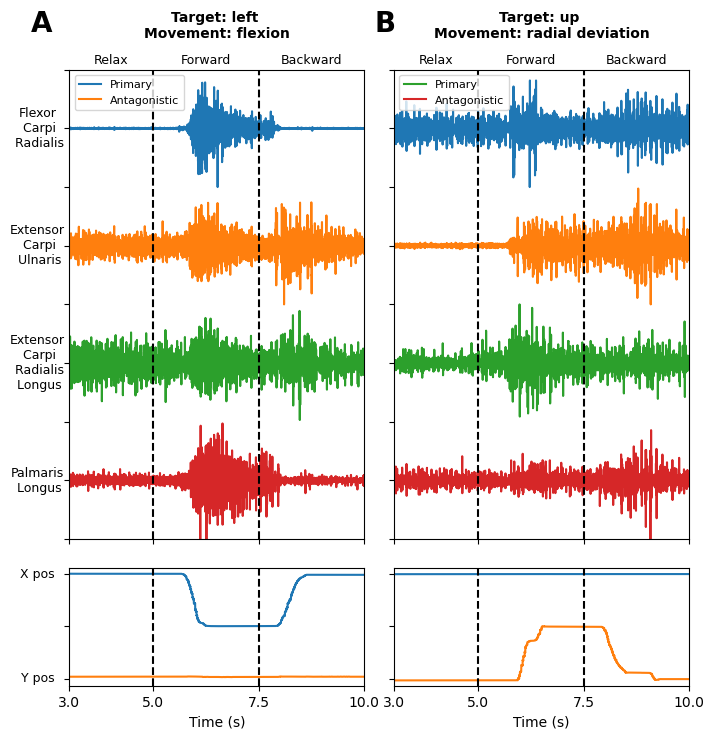

In [16]:
data3D_EMG = epochs_emg_pre.get_data() # Get all epochs data in a 3D matrix (trials x channels x samples
epochsKinematictmp = epochs_kin_pre.copy()

# dropped_indices = [n for n, dl in enumerate(epochsEMG.drop_log) if len(dl)] # Indices of rejected epochs
# epochsKinematictmp = epochsKinematictmp.drop(dropped_indices) # Drop corresponding kinematic epochs

data3D_Kinematic = epochsKinematictmp.get_data() #


time = np.zeros(shape=(data3D_EMG.shape[2]), dtype=np.float32)
targets = epochs_emg_pre.events[:,2]
muscle1 = muscle2 = muscle3 = muscle4 = np.zeros(shape=(data3D_EMG.shape[2]), dtype=np.float32)

movement = {1: "flexion", 2: "extension", 3: "radial deviation", 4: "ulnar deviation", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}
target = {1: "left", 2: "right", 3: "up", 4: "down", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}

for x in range(data3D_EMG.shape[2]):
    time[x] = x * 1/FS

#select a random flexion trial
movement_code = 1       # 1=Flexión
indices = np.where(targets == movement_code)[0]

selected_trial = np.random.choice(indices) #Trial to be plotted
#muscle data 
muscle1 = data3D_EMG[selected_trial,0,:] - data3D_EMG[selected_trial,1,:] #Extensor Carpi Radialis Longus, associated with the radial deviation movement
muscle2 = data3D_EMG[selected_trial,2,:] - data3D_EMG[selected_trial,3,:] #Extensor Carpi Ulnaris, associated with the extension movement
muscle3 = data3D_EMG[selected_trial,4,:] - data3D_EMG[selected_trial,5,:] #Flexor Carpi Radialis, associated with the flexion movement
muscle4 = data3D_EMG[selected_trial,6,:] - data3D_EMG[selected_trial,7,:] #Palmaris Longus, associated with the ulnar deviation movement
NormalizedMuscle1 = muscle1/np.max(np.abs(muscle1))
NormalizedMuscle2 = muscle2/np.max(np.abs(muscle2))
NormalizedMuscle3 = muscle3/np.max(np.abs(muscle3))
NormalizedMuscle4 = muscle4/np.max(np.abs(muscle4))
X = data3D_Kinematic[selected_trial,0,:]
Y = data3D_Kinematic[selected_trial,1,:]

#If variance is lower than a threshold, then normalize against the value reported in the literature
if np.var(X) < 1:
    NormalizedX = X / 90
else:
    NormalizedX = X/np.max(np.abs(X))
if np.var(Y) < 1:
    NormalizedY = Y / 45
else:
    NormalizedY = Y/np.max(np.abs(Y))

if 1:#target[targets[selected_trial]] == "up" or target[targets[selected_trial]] == "down":
    print("Trial %d (%s)" %(selected_trial,movement[targets[selected_trial]]))
    from matplotlib import gridspec
    
    fig,axs = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                    'height_ratios': [4, 1],
                    'wspace': 0.1,
                    'hspace': 0.1})
    axs[0,0].set_title("Target: {} \nMovement: {}".format(target[targets[selected_trial]], movement[targets[selected_trial]]), fontsize=10, y=1.05, fontweight='bold')
    axs[0,0].plot(time[1536:], NormalizedMuscle3[1536:] + 6, label='Primary')
    axs[0,0].plot(time[1536:], NormalizedMuscle2[1536:] + 4, label='Antagonistic')
    axs[0,0].plot(time[1536:], NormalizedMuscle1[1536:] + 2)
    axs[0,0].plot(time[1536:], NormalizedMuscle4[1536:])
    axs[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[0,0].set_xticks(xticks)
    axs[0,0].set_yticklabels([]) 
    axs[0,0].set_xlim(3,10)
    axs[0,0].set_ylim(-1.,7.)
    axs[0,0].legend(loc='upper left', fontsize=8)



    xmin = axs[0,0].get_xlim()[0] #(previous y location: 0, 2.5, 5, 7.5)
    axs[0,0].text(xmin-0.75, 0, 'Palmaris\n Longus', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 2, 'Extensor\n Carpi\n Radialis\n Longus', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 4, 'Extensor\n Carpi\n Ulnaris', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(xmin-0.75, 6, 'Flexor\n Carpi\n Radialis', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    # add text just above the top axis
    ymax = axs[0,0].get_ylim()[1]
    axs[0,0].text(4, ymax+0.05, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(6.25, ymax+0.05, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,0].text(8.75, ymax+0.05, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,0].set_xlabel('Time (s)')
    axs[1,0].plot(time[1536:], NormalizedX[1536:] + 2)
    axs[1,0].plot(time[1536:], NormalizedY[1536:])
    axs[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[1,0].set_xticks(xticks)
    axs[1,0].set_yticklabels([]) 
    # add text just left the left axis
    xmin = axs[1,0].get_xlim()[0]
    axs[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

    # the other two grpahs

    #select a random radial deviation trial
    movement_code = 3       # 3=Radial Deviation
    indices = np.where(targets == movement_code)[0]

    selected_trial = np.random.choice(indices) #Trial to be plotted
    print("Trial %d (%s)" %(selected_trial,movement[targets[selected_trial]]))
    #muscle data 
    muscle1 = data3D_EMG[selected_trial,0,:] - data3D_EMG[selected_trial,1,:] #Extensor Carpi Radialis Longus, associated with the radial deviation movement
    muscle2 = data3D_EMG[selected_trial,2,:] - data3D_EMG[selected_trial,3,:] #Extensor Carpi Ulnaris, associated with the extension movement
    muscle3 = data3D_EMG[selected_trial,4,:] - data3D_EMG[selected_trial,5,:] #Flexor Carpi Radialis, associated with the flexion movement
    muscle4 = data3D_EMG[selected_trial,6,:] - data3D_EMG[selected_trial,7,:] #Palmaris Longus, associated with the ulnar deviation movement
    NormalizedMuscle1 = muscle1/np.max(np.abs(muscle1))
    NormalizedMuscle2 = muscle2/np.max(np.abs(muscle2))
    NormalizedMuscle3 = muscle3/np.max(np.abs(muscle3))
    NormalizedMuscle4 = muscle4/np.max(np.abs(muscle4))
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]
    #If variance is lower than a threshold, then normalize against the value reported in the literature
    if np.var(X) < 1:
        NormalizedX = X / 90
    else:
        NormalizedX = X/np.max(np.abs(X))
    if np.var(Y) < 1:
        NormalizedY = Y / 45
    else:
        NormalizedY = Y/np.max(np.abs(Y))

    axs[0,1].set_title("Target: {} \nMovement: {}".format(target[targets[selected_trial]], movement[targets[selected_trial]]), fontsize=10, y=1.05, fontweight='bold')
    axs[0,1].plot(time[1536:], NormalizedMuscle3[1536:] + 6)
    axs[0,1].plot(time[1536:], NormalizedMuscle2[1536:] + 4)
    axs[0,1].plot(time[1536:], NormalizedMuscle1[1536:] + 2, label='Primary')
    axs[0,1].plot(time[1536:], NormalizedMuscle4[1536:], label='Antagonistic')

    axs[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[0,1].set_xticks(xticks)
    axs[0,1].set_yticklabels([])
    axs[0,1].set_xlim(3,10)
    axs[0,1].set_ylim(-1.,7.) 
    axs[0,1].legend(loc='upper left', fontsize=8)

    # add text just above the top axis
    ymax = axs[0,1].get_ylim()[1]
    axs[0,1].text(4, ymax+0.05, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,1].text(6.25, ymax+0.05, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[0,1].text(8.75, ymax+0.05, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
    axs[1,1].set_xlabel('Time (s)')
    axs[1,1].plot(time[1536:], NormalizedX[1536:] + 2)
    axs[1,1].plot(time[1536:], NormalizedY[1536:])
    axs[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
    axs[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
    xticks = [3, 5, 7.5, 10]
    axs[1,1].set_xticks(xticks)
    axs[1,1].set_yticklabels([]) 

    fig.text(0.09, 0.92, 'A', ha='center', va='bottom', fontsize=20, rotation=0, color='k', zorder=11, fontweight='bold')
    fig.text(0.52, 0.92, 'B', ha='center', va='bottom', fontsize=20, rotation=0, color='k', zorder=11, fontweight='bold')
    

    fig.tight_layout()
    plt.show()

    output_path = os.path.join(output_dir, f"sub-{subject}_EMG.pdf")
    fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# 2) Encoder Data

Dropped 0 epochs: 


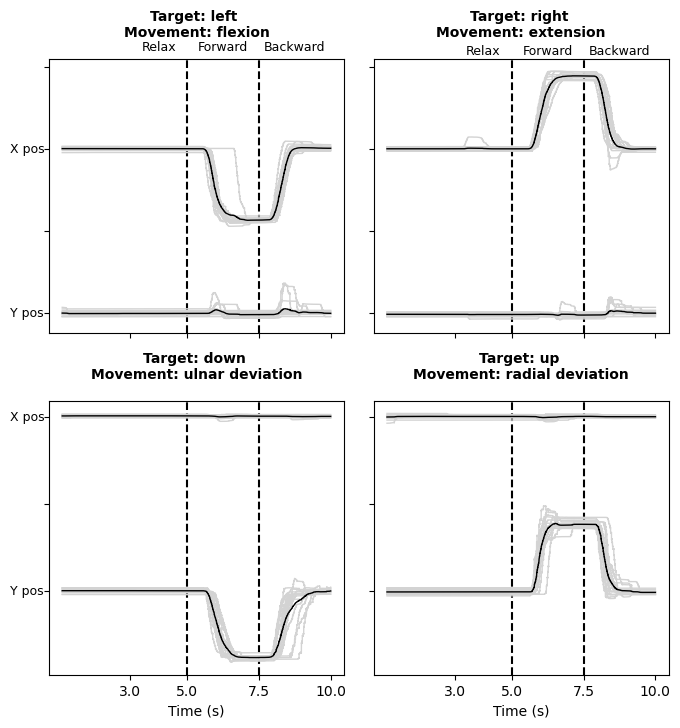

Text(0.5, 0, 'Time (s)')

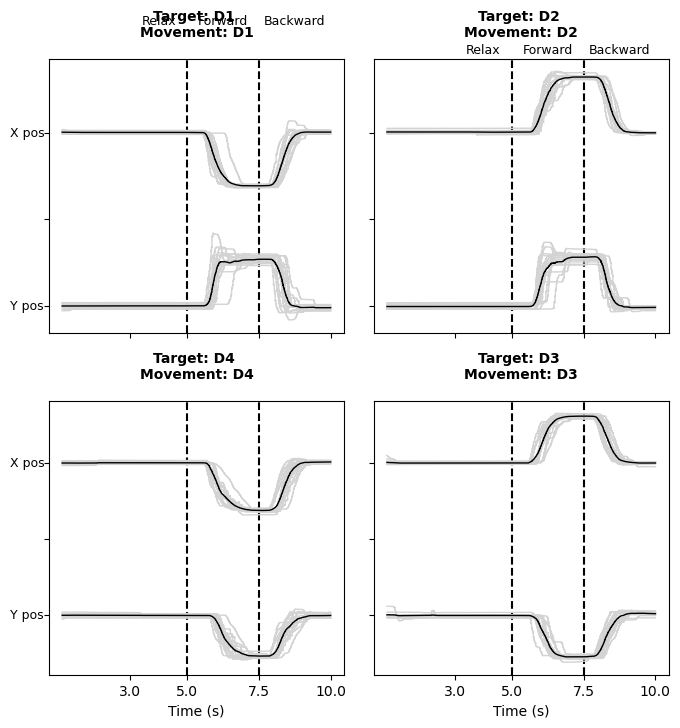

In [17]:
epochsKinematictmp = epochs_kin_pre.copy()

def custom_rejection_criteria(epoch_data):
    # Define custom rejection criteria
    max_amplitude = 100  # Example threshold in units of the data
    if (np.max(np.abs(epoch_data), axis=1) > max_amplitude).any():
        return True  # Reject epoch
    return False  # Keep epoch  

# Apply the custom function to each epoch to create a boolean mask
# This creates a list of booleans, where True means the epoch is "bad" according to the function
bad_epochs_mask = [custom_rejection_criteria(epoch) for epoch in epochsKinematictmp.get_data()]

# Drop the bad epochs using the mask
# The 'drop' method can take a boolean mask or indices
epochsKinematictmp.drop(bad_epochs_mask, reason='custom_criteria')

data3D_Kinematic = epochsKinematictmp.get_data() #

event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4}
data3D_Kinematic_Flexion = epochsKinematictmp['1'].get_data()
data3D_Kinematic_Extension = epochsKinematictmp['2'].get_data()
data3D_Kinematic_Radial = epochsKinematictmp['3'].get_data()
data3D_Kinematic_Ulnar = epochsKinematictmp['4'].get_data()

data3D_D1 = epochsKinematictmp['5'].get_data()
data3D_D2 = epochsKinematictmp['6'].get_data()
data3D_D3 = epochsKinematictmp['7'].get_data()
data3D_D4 = epochsKinematictmp['8'].get_data()

Normalized_Flexion = np.zeros(shape=(data3D_Kinematic_Flexion.shape[0], data3D_Kinematic_Flexion.shape[1], data3D_Kinematic_Flexion.shape[2]), dtype=np.float32)
Normalized_Extension = np.zeros(shape=(data3D_Kinematic_Extension.shape[0], data3D_Kinematic_Extension.shape[1], data3D_Kinematic_Extension.shape[2]), dtype=np.float32)
Normalized_Radial = np.zeros(shape=(data3D_Kinematic_Radial.shape[0], data3D_Kinematic_Radial.shape[1], data3D_Kinematic_Radial.shape[2]), dtype=np.float32)
Normalized_Ulnar = np.zeros(shape=(data3D_Kinematic_Ulnar.shape[0], data3D_Kinematic_Ulnar.shape[1], data3D_Kinematic_Ulnar.shape[2]), dtype=np.float32)

Normalized_D1 = np.zeros(shape=(data3D_D1.shape[0], data3D_D1.shape[1], data3D_D1.shape[2]), dtype=np.float32)
Normalized_D2 = np.zeros(shape=(data3D_D2.shape[0], data3D_D2.shape[1], data3D_D2.shape[2]), dtype=np.float32)
Normalized_D3 = np.zeros(shape=(data3D_D3.shape[0], data3D_D3.shape[1], data3D_D3.shape[2]), dtype=np.float32)
Normalized_D4 = np.zeros(shape=(data3D_D4.shape[0], data3D_D4.shape[1], data3D_D4.shape[2]), dtype=np.float32)

flex_count = extension_count = radial_count = ulnar_count = D1_count = D2_count = D3_count = D4_count = 0

targets = epochsKinematictmp.events[:,2]

time = np.zeros(shape=(data3D_Kinematic.shape[2]), dtype=np.float32)

for x in range(data3D_Kinematic.shape[2]):
    time[x] = x * 1/FS



for selected_trial in range(0,epochsKinematictmp.get_data().shape[0]):
    #encoders data
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]
    NormalizedY = Y / 90
    NormalizedX = X / 90
    
    if targets[selected_trial] == 1:        
        Normalized_Flexion[flex_count,0,:] = NormalizedX
        Normalized_Flexion[flex_count,1,:] = NormalizedY
        flex_count += 1
    elif targets[selected_trial] == 2:
        Normalized_Extension[extension_count,0,:] = NormalizedX
        Normalized_Extension[extension_count,1,:] = NormalizedY
        extension_count += 1
    elif targets[selected_trial] == 3:
        Normalized_Radial[radial_count,0,:] = NormalizedX
        Normalized_Radial[radial_count,1,:] = NormalizedY
        radial_count += 1
    elif targets[selected_trial] == 4:
        Normalized_Ulnar[ulnar_count,0,:] = NormalizedX
        Normalized_Ulnar[ulnar_count,1,:] = NormalizedY
        ulnar_count += 1
    elif targets[selected_trial] == 5:
        Normalized_D1[D1_count,0,:] = NormalizedX
        Normalized_D1[D1_count,1,:] = NormalizedY
        D1_count += 1
    elif targets[selected_trial] == 6:
        Normalized_D2[D2_count,0,:] = NormalizedX
        Normalized_D2[D2_count,1,:] = NormalizedY
        D2_count += 1
    elif targets[selected_trial] == 7:
        Normalized_D3[D3_count,0,:] = NormalizedX
        Normalized_D3[D3_count,1,:] = NormalizedY
        D3_count += 1
    elif targets[selected_trial] == 8:
        Normalized_D4[D4_count,0,:] = NormalizedX
        Normalized_D4[D4_count,1,:] = NormalizedY
        D4_count += 1
    
from matplotlib import gridspec

fig,axs = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                'height_ratios': [1, 1],
                'wspace': 0.1,
                'hspace': 0.25})

#Flexion plots
axs[0,0].set_title("Target: left \nMovement: flexion", fontsize=10, y=1.05, fontweight='bold')

axs[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs[0,0].set_xticks(xticks)
axs[0,0].set_yticks(yticks)
axs[0,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_Flexion.shape[0]):
    axs[0,0].plot(time[1536:], Normalized_Flexion[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[0,0].plot(time[1536:], Normalized_Flexion[i,1,1536:], color='lightgray', linewidth=1)

axs[0,0].plot(time[1536:], np.mean(Normalized_Flexion[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[0,0].plot(time[1536:], np.mean(Normalized_Flexion[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs[1,0].get_xlim()[0]
axs[0,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

# add text just above the top axis
ymax = axs[0,0].get_ylim()[1]
axs[0,0].text(4, ymax+0.96, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(6.25, ymax+0.96, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,0].text(8.75, ymax+0.96, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#Extension plots
axs[0,1].set_title("Target: right \nMovement: extension", fontsize=10, y=1.05, fontweight='bold')

axs[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs[0,1].set_xticks(xticks)
axs[0,1].set_yticks(yticks)
axs[0,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_Extension.shape[0]):
    axs[0,1].plot(time[1536:], Normalized_Extension[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[0,1].plot(time[1536:], Normalized_Extension[i,1,1536:], color='lightgray', linewidth=1)

axs[0,1].plot(time[1536:], np.mean(Normalized_Extension[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[0,1].plot(time[1536:], np.mean(Normalized_Extension[:,1,1536:], axis=0), color='black', linewidth=1)

# add text just above the top axis
ymax = axs[0,1].get_ylim()[1]
axs[0,1].text(4, ymax+0.02, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,1].text(6.25, ymax+0.02, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs[0,1].text(8.75, ymax+0.02, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#Radial Deviation plots
axs[1,1].set_title("Target: up \nMovement: radial deviation", fontsize=10, y=1.05, fontweight='bold')

axs[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 2]
axs[1,1].set_xticks(xticks)
axs[1,1].set_yticks(yticks)
axs[1,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_Radial.shape[0]):
    axs[1,1].plot(time[1536:], Normalized_Radial[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[1,1].plot(time[1536:], Normalized_Radial[i,1,1536:], color='lightgray', linewidth=1)

axs[1,1].plot(time[1536:], np.mean(Normalized_Radial[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[1,1].plot(time[1536:], np.mean(Normalized_Radial[:,1,1536:], axis=0), color='black', linewidth=1)

axs[1,1].set_xlabel('Time (s)')

#Ulnar deviation plots
axs[1,0].set_title("Target: down \nMovement: ulnar deviation", fontsize=10, y=1.05, fontweight='bold')

axs[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [-1, 0, 1, 2]
axs[1,0].set_xticks(xticks)
axs[1,0].set_yticks(yticks)
axs[1,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_Ulnar.shape[0]):
    axs[1,0].plot(time[1536:], Normalized_Ulnar[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs[1,0].plot(time[1536:], Normalized_Ulnar[i,1,1536:], color='lightgray', linewidth=1)

axs[1,0].plot(time[1536:], np.mean(Normalized_Ulnar[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs[1,0].plot(time[1536:], np.mean(Normalized_Ulnar[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs[1,0].get_xlim()[0]
axs[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

axs[1,0].set_xlabel('Time (s)')

plt.show()
output_path = os.path.join(output_dir, f"sub-{subject}_Encoders.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

fig2,axs2 = plt.subplots(2,2, figsize=(8, 8), sharex='col', sharey='row', gridspec_kw={
                'height_ratios': [1, 1],
                'wspace': 0.1,
                'hspace': 0.25})

#D1 plots
axs2[0,0].set_title("Target: D1 \nMovement: D1", fontsize=10, y=1.05, fontweight='bold')

axs2[0,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[0,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs2[0,0].set_xticks(xticks)
axs2[0,0].set_yticks(yticks)
axs2[0,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_D1.shape[0]):
    axs2[0,0].plot(time[1536:], Normalized_D1[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[0,0].plot(time[1536:], Normalized_D1[i,1,1536:], color='lightgray', linewidth=1)

axs2[0,0].plot(time[1536:], np.mean(Normalized_D1[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[0,0].plot(time[1536:], np.mean(Normalized_D1[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs2[0,0].get_xlim()[0]
axs2[0,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

# add text just above the top axis
ymax = axs2[0,0].get_ylim()[1]
axs2[0,0].text(4, ymax+0.96, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(6.25, ymax+0.96, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,0].text(8.75, ymax+0.96, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#D2 plots
axs2[0,1].set_title("Target: D2 \nMovement: D2", fontsize=10, y=1.05, fontweight='bold')

axs2[0,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[0,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 1, 2, 3]
axs2[0,1].set_xticks(xticks)
axs2[0,1].set_yticks(yticks)
axs2[0,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_D2.shape[0]):
    axs2[0,1].plot(time[1536:], Normalized_D2[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[0,1].plot(time[1536:], Normalized_D2[i,1,1536:], color='lightgray', linewidth=1)

axs2[0,1].plot(time[1536:], np.mean(Normalized_D2[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[0,1].plot(time[1536:], np.mean(Normalized_D2[:,1,1536:], axis=0), color='black', linewidth=1)

# add text just above the top axis
ymax = axs2[0,1].get_ylim()[1]
axs2[0,1].text(4, ymax+0.02, 'Relax', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,1].text(6.25, ymax+0.02, 'Forward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)
axs2[0,1].text(8.75, ymax+0.02, 'Backward', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11)

#D3 plots
axs2[1,1].set_title("Target: D3 \nMovement: D3", fontsize=10, y=1.05, fontweight='bold')

axs2[1,1].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[1,1].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [0, 2]
axs2[1,1].set_xticks(xticks)
axs2[1,1].set_yticks(yticks)
axs2[1,1].set_yticklabels([]) 

#plot data
for i in range(Normalized_D3.shape[0]):
    axs2[1,1].plot(time[1536:], Normalized_D3[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[1,1].plot(time[1536:], Normalized_D3[i,1,1536:], color='lightgray', linewidth=1)

axs2[1,1].plot(time[1536:], np.mean(Normalized_D3[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[1,1].plot(time[1536:], np.mean(Normalized_D3[:,1,1536:], axis=0), color='black', linewidth=1)

axs2[1,1].set_xlabel('Time (s)')

#D4plots
axs2[1,0].set_title("Target: D4 \nMovement: D4", fontsize=10, y=1.05, fontweight='bold')

axs2[1,0].axvline(x = 5.0, color= 'black', linestyle = 'dashed')  
axs2[1,0].axvline(x = 7.5, color= 'black', linestyle = 'dashed')
xticks = [3, 5, 7.5, 10]
yticks = [-1, 0, 1, 2]
axs2[1,0].set_xticks(xticks)
axs2[1,0].set_yticks(yticks)
axs2[1,0].set_yticklabels([]) 

#plot data
for i in range(Normalized_D4.shape[0]):
    axs2[1,0].plot(time[1536:], Normalized_D4[i,0,1536:] + 2, color='lightgray', linewidth=1)
    axs2[1,0].plot(time[1536:], Normalized_D4[i,1,1536:], color='lightgray', linewidth=1)

axs2[1,0].plot(time[1536:], np.mean(Normalized_D4[:,0,1536:], axis=0) + 2, color='black', linewidth=1)
axs2[1,0].plot(time[1536:], np.mean(Normalized_D4[:,1,1536:], axis=0), color='black', linewidth=1)

 
# add text just left the left axis
xmin = axs2[1,0].get_xlim()[0]
axs2[1,0].text(xmin-0.75, 0, 'Y pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)
axs2[1,0].text(xmin-0.75, 2, 'X pos', ha='center', va='center', fontsize=9, rotation=0, color='k', zorder=11)

axs2[1,0].set_xlabel('Time (s)')

# 3) Kinematic metrics

Dropped 0 epochs: 


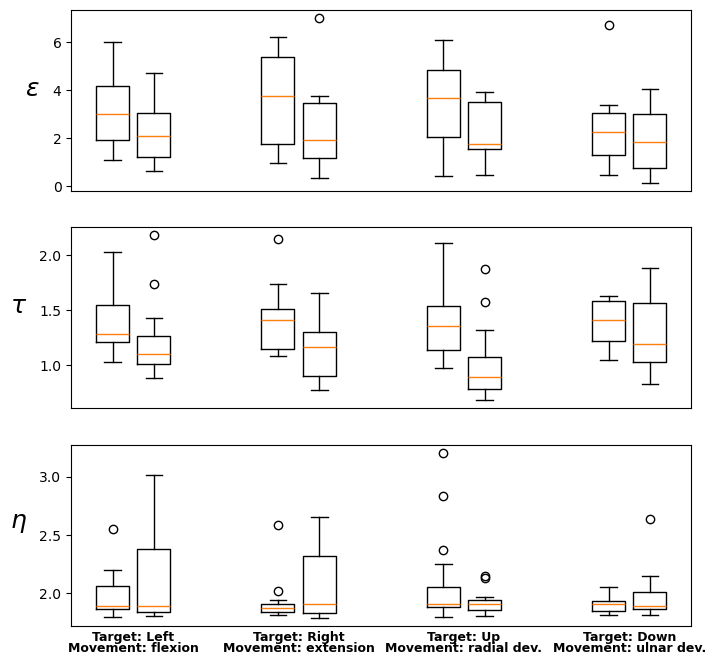

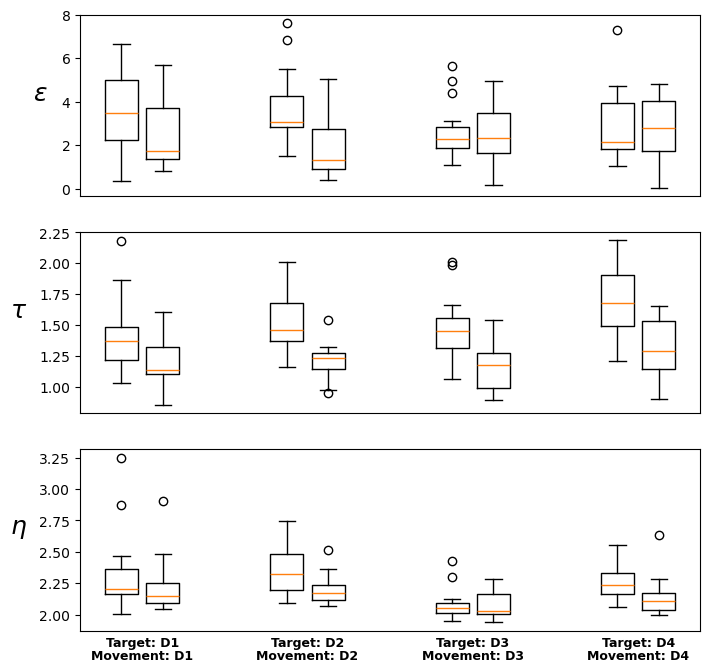

In [18]:
# def custom_rejection_criteria(epoch_data):
#     # Define custom rejection criteria
#     max_amplitude = 100  # Example threshold in units of the data
#     if (np.max(np.abs(epoch_data), axis=1) > max_amplitude).any():
#         return True  # Reject epoch
#     return False  # Keep epoch  

# # Apply the custom function to each epoch to create a boolean mask
# # This creates a list of booleans, where True means the epoch is "bad" according to the function
# bad_epochs_mask = [custom_rejection_criteria(epoch) for epoch in epochsKinematictmp.get_data()]

# # Drop the bad epochs using the mask
# # The 'drop' method can take a boolean mask or indices
# epochsKinematictmp.drop(bad_epochs_mask, reason='custom_criteria')

# data3D_Kinematic = epochsKinematictmp.get_data()

data3D_EMG = epochs_emg_pre.get_data() # Get all epochs data in a 3D matrix (trials x channels x samples
epochsKinematictmp = epochs_kin_pre.copy()

dropped_indices = [n for n, dl in enumerate(epochs_emg_pre.drop_log) if len(dl)] # Indices of rejected epochs
epochsKinematictmp = epochsKinematictmp.drop(dropped_indices) # Drop corresponding kinematic epochs

data3D_Kinematic = epochsKinematictmp.get_data()

time = np.zeros(shape=(data3D_Kinematic.shape[2]), dtype=np.float32)
movement = {1: "Flexion", 2: "Extension", 3: "Radial D.", 4: "Ulnar D.", 5: "D1", 6: "D2", 7: "D3", 8: "D4"}

for x in range(data3D_Kinematic.shape[2]):
    time[x] = x * 1/FS

MotorPerformanceIndices = np.zeros(shape=(data3D_Kinematic.shape[0],6), dtype=np.float32)

for selected_trial in range(0,data3D_Kinematic.shape[0]-1):    
    #Computing motor performance indices
    X = data3D_Kinematic[selected_trial,0,:]
    Y = data3D_Kinematic[selected_trial,1,:]

    MotorPerformanceIndices[selected_trial, 0] = ComputeAccuracy(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "FORWARD")
    MotorPerformanceIndices[selected_trial, 1] = ComputeAccuracy(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "BACKWARD")

    MotorPerformanceIndices[selected_trial, 2] = ComputeExcecutionTime(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "FORWARD")
    MotorPerformanceIndices[selected_trial, 3] = ComputeExcecutionTime(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "BACKWARD")

    MotorPerformanceIndices[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "FORWARD")
    MotorPerformanceIndices[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= movement[targets[selected_trial]], RawData= np.array([X,Y]), movementDirection= "BACKWARD")

# Define nombres de columnas (siguiendo el orden de tus métricas)
columns = [
    'Accuracy_ForwardMovement', 'Accuracy_BackwardMovement',
    'ExecutionTime_ForwardMovement', 'ExecutionTime_BackwardMovement',
    'TrajectoryEfficiency_ForwardMovement', 'TrajectoryEfficiency_BackwardMovement'
]

# Crea un DataFrame a partir del array de métricas
df = pd.DataFrame(MotorPerformanceIndices, columns=columns)

# Añade columna de índice de trial (opcional)
df.insert(0, 'trial', df.index)

# Guarda como .tsv
output_path = os.path.join(output_dir, f"sub-{subject}_MotorPerformanceMetrics.tsv")
df.to_csv(output_path, sep='\t', index=False)

####Motor Performance Indices Box Plots

event_id= {"Flexion":1, "Extension":2, "Radial D.":3, "Ulnar D.":4, "D1":5, "D2":6, "D3":7, "D4":8}

data3D_Kinematic_Flexion = epochs_kin_pre['1'].get_data()
data3D_Kinematic_Extension = epochs_kin_pre['2'].get_data()
data3D_Kinematic_Radial = epochs_kin_pre['3'].get_data()
data3D_Kinematic_Ulnar = epochs_kin_pre['4'].get_data()
data3D_D1 = epochs_kin_pre['5'].get_data()
data3D_D2 = epochs_kin_pre['6'].get_data()
data3D_D3 = epochs_kin_pre['7'].get_data()
data3D_D4 = epochs_kin_pre['8'].get_data()

MotorPerformanceIndicesFlexion = np.zeros(shape=(data3D_Kinematic_Flexion.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesExtension = np.zeros(shape=(data3D_Kinematic_Extension.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesRadialD = np.zeros(shape=(data3D_Kinematic_Radial.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesUlnarD = np.zeros(shape=(data3D_Kinematic_Ulnar.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD1 = np.zeros(shape=(data3D_D1.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD2 = np.zeros(shape=(data3D_D2.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD3 = np.zeros(shape=(data3D_D3.shape[0],8), dtype=np.float32)
MotorPerformanceIndicesD4 = np.zeros(shape=(data3D_D4.shape[0],8), dtype=np.float32)

#Compute Motor Performance Indices for each movement type
for selected_trial in range(0,data3D_Kinematic_Flexion.shape[0]):    
    #Computing motor performance indices
    X_Flexion = data3D_Kinematic_Flexion[selected_trial,0,:]
    Y_Flexion = data3D_Kinematic_Flexion[selected_trial,1,:]
    X_Extension = data3D_Kinematic_Extension[selected_trial,0,:]
    Y_Extension = data3D_Kinematic_Extension[selected_trial,1,:]
    X_RadialD = data3D_Kinematic_Radial[selected_trial,0,:]
    Y_RadialD = data3D_Kinematic_Radial[selected_trial,1,:]
    X_UlnarD = data3D_Kinematic_Ulnar[selected_trial,0,:]
    Y_UlnarD = data3D_Kinematic_Ulnar[selected_trial,1,:]
    X_D1 = data3D_D1[selected_trial,0,:]
    Y_D1 = data3D_D1[selected_trial,1,:]
    X_D2 = data3D_D2[selected_trial,0,:]
    Y_D2 = data3D_D2[selected_trial,1,:]
    X_D3 = data3D_D3[selected_trial,0,:]
    Y_D3 = data3D_D3[selected_trial,1,:]
    X_D4 = data3D_D4[selected_trial,0,:]
    Y_D4 = data3D_D4[selected_trial,1,:]


    MotorPerformanceIndicesFlexion[selected_trial, 0] = ComputeAccuracy(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 1] = ComputeAccuracy(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 2] = ComputeExcecutionTime(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 3] = ComputeExcecutionTime(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 6] = CheckStarAndEndPoints(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "FORWARD")
    MotorPerformanceIndicesFlexion[selected_trial, 7] = CheckStarAndEndPoints(movement= "Flexion", RawData= np.array([X_Flexion,Y_Flexion]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesExtension[selected_trial, 0] = ComputeAccuracy(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 1] = ComputeAccuracy(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesExtension[selected_trial, 2] = ComputeExcecutionTime(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 3] = ComputeExcecutionTime(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesExtension[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesExtension[selected_trial, 6] = CheckStarAndEndPoints(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "FORWARD")
    MotorPerformanceIndicesExtension[selected_trial, 7] = CheckStarAndEndPoints(movement= "Extension", RawData= np.array([X_Extension,Y_Extension]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesRadialD[selected_trial, 0] = ComputeAccuracy(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 1] = ComputeAccuracy(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 2] = ComputeExcecutionTime(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 3] = ComputeExcecutionTime(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 6] = CheckStarAndEndPoints(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesRadialD[selected_trial, 7] = CheckStarAndEndPoints(movement= "Radial D.", RawData= np.array([X_RadialD,Y_RadialD]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesUlnarD[selected_trial, 0] = ComputeAccuracy(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 1] = ComputeAccuracy(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 2] = ComputeExcecutionTime(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 3] = ComputeExcecutionTime(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 6] = CheckStarAndEndPoints(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "FORWARD")
    MotorPerformanceIndicesUlnarD[selected_trial, 7] = CheckStarAndEndPoints(movement= "Ulnar D.", RawData= np.array([X_UlnarD,Y_UlnarD]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesD1[selected_trial, 0] = ComputeAccuracy(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 1] = ComputeAccuracy(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD1[selected_trial, 2] = ComputeExcecutionTime(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 3] = ComputeExcecutionTime(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD1[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD1[selected_trial, 6] = CheckStarAndEndPoints(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD1[selected_trial, 7] = CheckStarAndEndPoints(movement= "D1", RawData= np.array([X_D1,Y_D1]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesD2[selected_trial, 0] = ComputeAccuracy(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 1] = ComputeAccuracy(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD2[selected_trial, 2] = ComputeExcecutionTime(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 3] = ComputeExcecutionTime(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD2[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD2[selected_trial, 6] = CheckStarAndEndPoints(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD2[selected_trial, 7] = CheckStarAndEndPoints(movement= "D2", RawData= np.array([X_D2,Y_D2]), movementDirection= "BACKWARD")

    MotorPerformanceIndicesD3[selected_trial, 0] = ComputeAccuracy(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 1] = ComputeAccuracy(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD3[selected_trial, 2] = ComputeExcecutionTime(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 3] = ComputeExcecutionTime(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD3[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D3", RawData=np.array([X_D3,Y_D3]), movementDirection="BACKWARD")
    MotorPerformanceIndicesD3[selected_trial, 6] = CheckStarAndEndPoints(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD3[selected_trial, 7] = CheckStarAndEndPoints(movement= "D3", RawData= np.array([X_D3,Y_D3]), movementDirection= "BACKWARD")


    MotorPerformanceIndicesD4[selected_trial, 0] = ComputeAccuracy(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 1] = ComputeAccuracy(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD4[selected_trial, 2] = ComputeExcecutionTime(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 3] = ComputeExcecutionTime(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD4[selected_trial, 4] = ComputeTrayectoryEfficiency(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 5] = ComputeTrayectoryEfficiency(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")
    MotorPerformanceIndicesD4[selected_trial, 6] = CheckStarAndEndPoints(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "FORWARD")
    MotorPerformanceIndicesD4[selected_trial, 7] = CheckStarAndEndPoints(movement= "D4", RawData= np.array([X_D4,Y_D4]), movementDirection= "BACKWARD")

# Función auxiliar para filtrar métricas basadas en la comprobación de inicio/fin y eliminar NaNs
def filter_valid_trials(matrix, metric_col, check_col):
    # Asume que la función de comprobación devuelve 1 (o valor > 0) si es válido
    valid_mask = matrix[:, check_col] > 0 
    data = matrix[valid_mask, metric_col]
    return data[~np.isnan(data)]

# Create a figure and an axes object
fig, axs = plt.subplots(3,1, figsize=(8, 8), sharex=True)

# Plot the box plot
axs[0].set_ylabel(r'$\varepsilon$', rotation='horizontal', fontsize=18, labelpad=15)
# Accuracy = [MotorPerformanceIndicesFlexion[:, 0], MotorPerformanceIndicesFlexion[:, 1], MotorPerformanceIndicesExtension[:, 0], MotorPerformanceIndicesExtension[:, 1],MotorPerformanceIndicesRadialD[:, 0], MotorPerformanceIndicesRadialD[:, 1],MotorPerformanceIndicesUlnarD[:, 0], MotorPerformanceIndicesUlnarD[:, 1]]
Accuracy = [
    filter_valid_trials(MotorPerformanceIndicesFlexion, 0, 6), filter_valid_trials(MotorPerformanceIndicesFlexion, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesExtension, 0, 6), filter_valid_trials(MotorPerformanceIndicesExtension, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesRadialD, 0, 6), filter_valid_trials(MotorPerformanceIndicesRadialD, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesUlnarD, 0, 6), filter_valid_trials(MotorPerformanceIndicesUlnarD, 1, 7)
]
axs[0].boxplot(Accuracy, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[1].set_ylabel(r'$\tau$', rotation='horizontal', fontsize=18, labelpad=15)
# Time = [MotorPerformanceIndicesFlexion[:, 2][~np.isnan(MotorPerformanceIndicesFlexion[:, 2])], MotorPerformanceIndicesFlexion[:, 3][~np.isnan(MotorPerformanceIndicesFlexion[:, 3])], MotorPerformanceIndicesExtension[:, 2][~np.isnan(MotorPerformanceIndicesExtension[:, 2])], MotorPerformanceIndicesExtension[:, 3][~np.isnan(MotorPerformanceIndicesExtension[:, 3])],MotorPerformanceIndicesRadialD[:, 2][~np.isnan(MotorPerformanceIndicesRadialD[:, 2])], MotorPerformanceIndicesRadialD[:, 3][~np.isnan(MotorPerformanceIndicesRadialD[:, 3])],MotorPerformanceIndicesUlnarD[:, 2][~np.isnan(MotorPerformanceIndicesUlnarD[:, 2])], MotorPerformanceIndicesUlnarD[:, 3][~np.isnan(MotorPerformanceIndicesUlnarD[:, 3])]]
Time = [
    filter_valid_trials(MotorPerformanceIndicesFlexion, 2, 6), filter_valid_trials(MotorPerformanceIndicesFlexion, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesExtension, 2, 6), filter_valid_trials(MotorPerformanceIndicesExtension, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesRadialD, 2, 6), filter_valid_trials(MotorPerformanceIndicesRadialD, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesUlnarD, 2, 6), filter_valid_trials(MotorPerformanceIndicesUlnarD, 3, 7)
]

axs[1].boxplot(Time, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[2].set_ylabel(r'$\eta$', rotation='horizontal', fontsize=18, labelpad=15)
# Efficiency = [MotorPerformanceIndicesFlexion[:, 4], MotorPerformanceIndicesFlexion[:, 5], MotorPerformanceIndicesExtension[:, 4], MotorPerformanceIndicesExtension[:, 5],MotorPerformanceIndicesRadialD[:, 4], MotorPerformanceIndicesRadialD[:, 5],MotorPerformanceIndicesUlnarD[:, 4], MotorPerformanceIndicesUlnarD[:, 5]]
Efficiency = [
    filter_valid_trials(MotorPerformanceIndicesFlexion, 4, 6), filter_valid_trials(MotorPerformanceIndicesFlexion, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesExtension, 4, 6), filter_valid_trials(MotorPerformanceIndicesExtension, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesRadialD, 4, 6), filter_valid_trials(MotorPerformanceIndicesRadialD, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesUlnarD, 4, 6), filter_valid_trials(MotorPerformanceIndicesUlnarD, 5, 7)
]
axs[2].boxplot(Efficiency, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs[2].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ymin = axs[2].get_ylim()[0]
axs[2].text(0.75, ymin-0.15, 'Target: Left', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(0.75, ymin-0.25, 'Movement: flexion', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(2.75, ymin-0.15, 'Target: Right', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(2.75, ymin-0.25, 'Movement: extension', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(4.75, ymin-0.15, 'Target: Up', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(4.75, ymin-0.25, 'Movement: radial dev.', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(6.75, ymin-0.15, 'Target: Down', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[2].text(6.75, ymin-0.25, 'Movement: ulnar dev.', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')


# Display the plot
plt.show()
output_path = os.path.join(output_dir, f"sub-{subject}_KinematicPerformanceMetrics.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# Create a figure and an axes object
fig2, axs2 = plt.subplots(3,1, figsize=(8, 8), sharex=True)

# Plot the box plot
axs2[0].set_ylabel(r'$\varepsilon$', rotation='horizontal', fontsize=18, labelpad=15)
# Accuracy = [MotorPerformanceIndicesD1[:, 0], MotorPerformanceIndicesD1[:, 1], MotorPerformanceIndicesD2[:, 0], MotorPerformanceIndicesD2[:, 1],MotorPerformanceIndicesD3[:, 0], MotorPerformanceIndicesD3[:, 1],MotorPerformanceIndicesD4[:, 0], MotorPerformanceIndicesD4[:, 1]]
Accuracy = [
    filter_valid_trials(MotorPerformanceIndicesD1, 0, 6), filter_valid_trials(MotorPerformanceIndicesD1, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesD2, 0, 6), filter_valid_trials(MotorPerformanceIndicesD2, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesD3, 0, 6), filter_valid_trials(MotorPerformanceIndicesD3, 1, 7),
    filter_valid_trials(MotorPerformanceIndicesD4, 0, 6), filter_valid_trials(MotorPerformanceIndicesD4, 1, 7)
]
axs2[0].boxplot(Accuracy, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[1].set_ylabel(r'$\tau$', rotation='horizontal', fontsize=18, labelpad=15)
# Time = [MotorPerformanceIndicesD1[:, 2][~np.isnan(MotorPerformanceIndicesD1[:, 2])], MotorPerformanceIndicesD1[:, 3][~np.isnan(MotorPerformanceIndicesD1[:, 3])], MotorPerformanceIndicesD2[:, 2][~np.isnan(MotorPerformanceIndicesD2[:, 2])], MotorPerformanceIndicesD2[:, 3][~np.isnan(MotorPerformanceIndicesD2[:, 3])],MotorPerformanceIndicesD3[:, 2][~np.isnan(MotorPerformanceIndicesD3[:, 2])], MotorPerformanceIndicesD3[:, 3][~np.isnan(MotorPerformanceIndicesD3[:, 3])],MotorPerformanceIndicesD4[:, 2][~np.isnan(MotorPerformanceIndicesD4[:, 2])], MotorPerformanceIndicesD4[:, 3][~np.isnan(MotorPerformanceIndicesD4[:, 3])]]
Time = [
    filter_valid_trials(MotorPerformanceIndicesD1, 2, 6), filter_valid_trials(MotorPerformanceIndicesD1, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesD2, 2, 6), filter_valid_trials(MotorPerformanceIndicesD2, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesD3, 2, 6), filter_valid_trials(MotorPerformanceIndicesD3, 3, 7),
    filter_valid_trials(MotorPerformanceIndicesD4, 2, 6), filter_valid_trials(MotorPerformanceIndicesD4, 3, 7)
]
axs2[1].boxplot(Time, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[2].set_ylabel(r'$\eta$', rotation='horizontal', fontsize=18, labelpad=15)
# Efficiency = [MotorPerformanceIndicesD1[:, 4], MotorPerformanceIndicesD1[:, 5], MotorPerformanceIndicesD2[:, 4], MotorPerformanceIndicesD2[:, 5],MotorPerformanceIndicesD3[:, 4], MotorPerformanceIndicesD3[:, 5],MotorPerformanceIndicesD4[:, 4], MotorPerformanceIndicesD4[:, 5]]
Efficiency = [
    filter_valid_trials(MotorPerformanceIndicesD1, 4, 6), filter_valid_trials(MotorPerformanceIndicesD1, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesD2, 4, 6), filter_valid_trials(MotorPerformanceIndicesD2, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesD3, 4, 6), filter_valid_trials(MotorPerformanceIndicesD3, 5, 7),
    filter_valid_trials(MotorPerformanceIndicesD4, 4, 6), filter_valid_trials(MotorPerformanceIndicesD4, 5, 7)
]
axs2[2].boxplot(Efficiency, positions=[0.5,1,2.5,3,4.5,5,6.5,7], widths=0.4)
axs2[2].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

ymin = axs2[2].get_ylim()[0]
axs2[2].text(0.75, ymin-0.15, 'Target: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(0.75, ymin-0.25, 'Movement: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(2.75, ymin-0.15, 'Target: D2', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(2.75, ymin-0.25, 'Movement: D2', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(4.75, ymin-0.15, 'Target: D3', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(4.75, ymin-0.25, 'Movement: D3', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(6.75, ymin-0.15, 'Target: D4', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[2].text(6.75, ymin-0.25, 'Movement: D4', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')


# Display the plot
plt.show()

# 3.1) Kinematic metrics (New Test)

In [19]:
from scipy import stats  # <-- NUEVO: Para estadística rigurosa
from datetime import datetime

# Define aquí a los sujetos que deseas analizar
# Si procesaste todos en la Fase 1, pon los IDs aquí: ['1', '2', '3', ...]
subjects_to_analyze = ['3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19'] 
conditions = ['stim', 'sham']

# Mapeo simple: Código de evento -> Nombre del movimiento
event_map_names = {
    1: 'Flexion', 2: 'Extension', 3: 'Radial D.', 4: 'Ulnar D.',
    5: 'D1', 6: 'D2', 7: 'D3', 8: 'D4'
}

metric_names = ['accuracy', 'exec_time', 'efficiency']
titles = ['Precisión (Error Euclidiano)', 'Tiempo Ejecución (s)', 'Eficiencia de Trayectoria']
y_labels = ['Error', 'Segundos', 'Ratio (Real/Ideal)']

# --- NUEVO: DICCIONARIO DE SEGUIMIENTO GLOBAL ---
summary_results = {
    cond: {metric: {'mejora': 0, 'empeora': 0, 'neutro': 0, 'total': 0} for metric in metric_names}
    for cond in conditions
}

# ==============================================================================
# 1. FUNCIÓN DE EXTRACCIÓN CON FILTRO DE VALIDACIÓN DE MOVIMIENTO
# ==============================================================================
def extract_kinematic_metrics(epochs_kin, event_map, block_name=""):
    """
    Extrae precisión, tiempo y eficiencia solo para trials válidos,
    utilizando CheckStarAndEndPoints para descartar movimientos incorrectos.
    """
    metrics = {
        'forward': {'accuracy': [], 'exec_time': [], 'efficiency': []},
        'backward': {'accuracy': [], 'exec_time': [], 'efficiency': []}
    }
    
    # Extraer la matriz 3D (trials, channels, time) y los códigos de evento
    data = epochs_kin.get_data()
    events = epochs_kin.events[:, 2]
    
    valid_trials = {'forward': 0, 'backward': 0}
    discarded_trials = {'forward': 0, 'backward': 0}
    
    for trial_idx in range(len(events)):
        trial_data = data[trial_idx]
        movement_code = events[trial_idx]
        
        # Si el código (1-8) es válido
        if movement_code in event_map_names:
            mov_name = event_map_names[movement_code]
            
            # --- 1. EVALUAR FASE DE IDA (FORWARD) ---
            is_valid_fwd = CheckStarAndEndPoints(mov_name, trial_data, 'FORWARD')
            if is_valid_fwd == 1:
                acc_fwd = ComputeAccuracy(mov_name, trial_data, 'FORWARD')
                ext_fwd = ComputeExcecutionTime(mov_name, trial_data, 'FORWARD')
                eff_fwd = ComputeTrayectoryEfficiency(mov_name, trial_data, 'FORWARD')
                
                if not np.isnan(acc_fwd): metrics['forward']['accuracy'].append(acc_fwd)
                if not np.isnan(ext_fwd): metrics['forward']['exec_time'].append(ext_fwd)
                if not np.isnan(eff_fwd): metrics['forward']['efficiency'].append(eff_fwd)
                valid_trials['forward'] += 1
            else:
                discarded_trials['forward'] += 1
                
            # --- 2. EVALUAR FASE DE REGRESO (BACKWARD) ---
            is_valid_bwd = CheckStarAndEndPoints(mov_name, trial_data, 'BACKWARD')
            if is_valid_bwd == 1:
                acc_bwd = ComputeAccuracy(mov_name, trial_data, 'BACKWARD')
                ext_bwd = ComputeExcecutionTime(mov_name, trial_data, 'BACKWARD')
                eff_bwd = ComputeTrayectoryEfficiency(mov_name, trial_data, 'BACKWARD')
                
                if not np.isnan(acc_bwd): metrics['backward']['accuracy'].append(acc_bwd)
                if not np.isnan(ext_bwd): metrics['backward']['exec_time'].append(ext_bwd)
                if not np.isnan(eff_bwd): metrics['backward']['efficiency'].append(eff_bwd)
                valid_trials['backward'] += 1
            else:
                discarded_trials['backward'] += 1
                
    print(f"[{block_name.upper()}] Válidos -> FORWARD: {valid_trials['forward']} | BACKWARD: {valid_trials['backward']}")
    print(f"[{block_name.upper()}] Descartados -> FORWARD: {discarded_trials['forward']} | BACKWARD: {discarded_trials['backward']}")
    
    return metrics

# ==============================================================================
# 2. BUCLE PRINCIPAL (CON FILTRO DE SUJETOS PAREADOS)
# ==============================================================================
print("Iniciando pipeline de análisis estadístico cinemático (Diseño Pareado)...")

for subject in subjects_to_analyze:
    print(f"\n{'='*60}\n--- SUJETO {subject} ---\n{'='*60}")
    
    # 2.0 Diccionario temporal: Solo pasará al global si el sujeto completa ambas sesiones
    temp_subj_results = {cond: {metric: None for metric in metric_names} for cond in conditions}
    
    for condition in conditions:
        print(f"\n  CONDICIÓN: {condition.upper()}")
        
        file_kin_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_kin-epo.fif")
        file_kin_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_kin-epo.fif")
        
        if not os.path.exists(file_kin_pre) or not os.path.exists(file_kin_post):
            print(f"    [!] Faltan archivos .fif. Saltando condición.")
            continue
            
        try:
            epochs_kin_pre = mne.read_epochs(file_kin_pre, preload=True, verbose=False)
            epochs_kin_post = mne.read_epochs(file_kin_post, preload=True, verbose=False)
        except Exception as e:
            print(f"    [!] Error al cargar datos: {e}")
            continue

        metrics_pre = extract_kinematic_metrics(epochs_kin_pre, event_map_names, block_name="PRE ")
        metrics_post = extract_kinematic_metrics(epochs_kin_post, event_map_names, block_name="POST")

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        fig.suptitle(f'Métricas Cinemáticas Globales - Sujeto {subject} ({condition.upper()})', fontsize=16, fontweight='bold')

        valid_data_to_plot = False

        for i, metric in enumerate(metric_names):
            pre_data_combined = metrics_pre['forward'][metric] + metrics_pre['backward'][metric]
            post_data_combined = metrics_post['forward'][metric] + metrics_post['backward'][metric]
            
            if pre_data_combined and post_data_combined:
                valid_data_to_plot = True
                
                stat, p_val = stats.mannwhitneyu(pre_data_combined, post_data_combined, alternative='two-sided')
                med_pre = np.median(pre_data_combined)
                med_post = np.median(post_data_combined)
                
                if metric in ['accuracy', 'exec_time']:
                    tendencia_positiva = med_post < med_pre
                else:
                    tendencia_positiva = abs(med_post - 1.0) < abs(med_pre - 1.0)
                    
                significativo = p_val < 0.05
                
                print(f"    {titles[i]}: Mediana PRE: {med_pre:.3f} | POST: {med_post:.3f} | p = {p_val:.4e}")
                
                # GUARDAR RESULTADO EN CACHÉ TEMPORAL DEL SUJETO
                if significativo:
                    if tendencia_positiva:
                        print("      [!] SIGNIFICATIVO: MEJORA")
                        temp_subj_results[condition][metric] = 'mejora'
                    else:
                        print("      [!] SIGNIFICATIVO: EMPEORAMIENTO")
                        temp_subj_results[condition][metric] = 'empeora'
                else:
                    temp_subj_results[condition][metric] = 'neutro'
                
                # Gráfica
                bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
                colors = ['#aec7e8', '#ff9999']
                for patch, color in zip(bplot['boxes'], colors):
                    patch.set_facecolor(color)
                    
                sig_marker = "*" if significativo else ""
                axes[i].set_title(f"{titles[i]}\np = {p_val:.3e} {sig_marker}", fontsize=12)
                axes[i].set_ylabel(y_labels[i])
                axes[i].grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()

        if valid_data_to_plot:
            os.makedirs(output_dir, exist_ok=True)
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            output_filename = f"Kinematics_Global_sub-{subject}_cond-{condition}_{timestamp}.pdf"
            output_path = os.path.join(output_dir, output_filename)
            fig.savefig(output_path, dpi=600, format='pdf', bbox_inches='tight')
        plt.close(fig)

    # 2.1 EVALUACIÓN DE INTEGRIDAD DEL SUJETO AL FINALIZAR SUS CONDICIONES
    print(f"\n  [AUDITORÍA] Evaluando integridad de datos para el sujeto {subject}...")
    for metric in metric_names:
        if temp_subj_results['stim'][metric] is not None and temp_subj_results['sham'][metric] is not None:
            # El sujeto cuenta con ambas condiciones para esta métrica. Se añade al pool global.
            for cond in conditions:
                resultado_obtenido = temp_subj_results[cond][metric]
                summary_results[cond][metric][resultado_obtenido] += 1
                summary_results[cond][metric]['total'] += 1
        else:
            print(f"    [-] Métrica '{metric}' descartada del resumen. Falta una condición (Stim o Sham).")

# ==============================================================================
# 3. REPORTE FINAL DE POBLACIÓN (PAREADA)
# ==============================================================================
print("\n" + "="*70)
print("REPORTE GLOBAL DE SIGNIFICANCIA CLÍNICA (Sujetos Pareados, p < 0.05)")
print("="*70)

for i, metric in enumerate(metric_names):
    print(f"\n>> {titles[i].upper()}")
    for cond in conditions:
        res = summary_results[cond][metric]
        total = res['total']
        if total == 0:
            print(f"  [{cond.upper():4s}] Sin sujetos pareados válidos.")
            continue
            
        print(f"  [{cond.upper():4s}] N={total} | Mejoraron: {res['mejora']} | Empeoraron: {res['empeora']} | Sin cambio: {res['neutro']}")

print("\n" + "="*70)

Iniciando pipeline de análisis estadístico cinemático (Diseño Pareado)...

--- SUJETO 3 ---

  CONDICIÓN: STIM
[PRE ] Válidos -> FORWARD: 115 | BACKWARD: 113
[PRE ] Descartados -> FORWARD: 13 | BACKWARD: 15
[POST] Válidos -> FORWARD: 122 | BACKWARD: 122
[POST] Descartados -> FORWARD: 6 | BACKWARD: 6
    Precisión (Error Euclidiano): Mediana PRE: 1.914 | POST: 1.800 | p = 1.8925e-02
      [!] SIGNIFICATIVO: MEJORA
    Tiempo Ejecución (s): Mediana PRE: 1.489 | POST: 1.341 | p = 2.4020e-09
      [!] SIGNIFICATIVO: MEJORA
    Eficiencia de Trayectoria: Mediana PRE: 2.059 | POST: 2.045 | p = 7.6340e-02


C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combin


  CONDICIÓN: SHAM
    [!] Faltan archivos .fif. Saltando condición.

  [AUDITORÍA] Evaluando integridad de datos para el sujeto 3...
    [-] Métrica 'accuracy' descartada del resumen. Falta una condición (Stim o Sham).
    [-] Métrica 'exec_time' descartada del resumen. Falta una condición (Stim o Sham).
    [-] Métrica 'efficiency' descartada del resumen. Falta una condición (Stim o Sham).

--- SUJETO 4 ---

  CONDICIÓN: STIM
[PRE ] Válidos -> FORWARD: 128 | BACKWARD: 128
[PRE ] Descartados -> FORWARD: 0 | BACKWARD: 0
[POST] Válidos -> FORWARD: 128 | BACKWARD: 128
[POST] Descartados -> FORWARD: 0 | BACKWARD: 0
    Precisión (Error Euclidiano): Mediana PRE: 1.163 | POST: 1.257 | p = 6.1662e-01
    Tiempo Ejecución (s): Mediana PRE: 0.997 | POST: 0.954 | p = 7.0443e-03
      [!] SIGNIFICATIVO: MEJORA
    Eficiencia de Trayectoria: Mediana PRE: 2.309 | POST: 2.201 | p = 1.5293e-04
      [!] SIGNIFICATIVO: MEJORA


C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combin


  CONDICIÓN: SHAM
    [!] Faltan archivos .fif. Saltando condición.

  [AUDITORÍA] Evaluando integridad de datos para el sujeto 4...
    [-] Métrica 'accuracy' descartada del resumen. Falta una condición (Stim o Sham).
    [-] Métrica 'exec_time' descartada del resumen. Falta una condición (Stim o Sham).
    [-] Métrica 'efficiency' descartada del resumen. Falta una condición (Stim o Sham).

--- SUJETO 5 ---

  CONDICIÓN: STIM
[PRE ] Válidos -> FORWARD: 122 | BACKWARD: 121
[PRE ] Descartados -> FORWARD: 6 | BACKWARD: 7
[POST] Válidos -> FORWARD: 127 | BACKWARD: 125
[POST] Descartados -> FORWARD: 1 | BACKWARD: 3
    Precisión (Error Euclidiano): Mediana PRE: 1.893 | POST: 1.596 | p = 1.2970e-03
      [!] SIGNIFICATIVO: MEJORA
    Tiempo Ejecución (s): Mediana PRE: 1.095 | POST: 1.036 | p = 2.7126e-02
      [!] SIGNIFICATIVO: MEJORA
    Eficiencia de Trayectoria: Mediana PRE: 2.207 | POST: 2.146 | p = 1.0096e-01


C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combin

... (51 outputs left out)

C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combin


  CONDICIÓN: SHAM
[PRE ] Válidos -> FORWARD: 125 | BACKWARD: 125
[PRE ] Descartados -> FORWARD: 3 | BACKWARD: 3
[POST] Válidos -> FORWARD: 126 | BACKWARD: 121
[POST] Descartados -> FORWARD: 2 | BACKWARD: 7
    Precisión (Error Euclidiano): Mediana PRE: 2.029 | POST: 2.309 | p = 2.4731e-01
    Tiempo Ejecución (s): Mediana PRE: 1.129 | POST: 1.123 | p = 8.8107e-01
    Eficiencia de Trayectoria: Mediana PRE: 2.097 | POST: 2.056 | p = 3.5603e-01


C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combined, post_data_combined], labels=['Pre', 'Post'], patch_artist=True, widths=0.5)
C:\Users\jorge\AppData\Local\Temp\ipykernel_23112\2773452953.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot([pre_data_combin


  [AUDITORÍA] Evaluando integridad de datos para el sujeto 19...

REPORTE GLOBAL DE SIGNIFICANCIA CLÍNICA (Sujetos Pareados, p < 0.05)

>> PRECISIÓN (ERROR EUCLIDIANO)
  [STIM] N=13 | Mejoraron: 3 | Empeoraron: 4 | Sin cambio: 6
  [SHAM] N=13 | Mejoraron: 4 | Empeoraron: 3 | Sin cambio: 6

>> TIEMPO EJECUCIÓN (S)
  [STIM] N=13 | Mejoraron: 7 | Empeoraron: 2 | Sin cambio: 4
  [SHAM] N=13 | Mejoraron: 5 | Empeoraron: 1 | Sin cambio: 7

>> EFICIENCIA DE TRAYECTORIA
  [STIM] N=13 | Mejoraron: 6 | Empeoraron: 0 | Sin cambio: 7
  [SHAM] N=13 | Mejoraron: 4 | Empeoraron: 0 | Sin cambio: 9



# 3.2) ANÁLISIS ESPECTRAL DE EEG (Banda Alfa, Beta y Mu)

Sin rechazos por amplitud


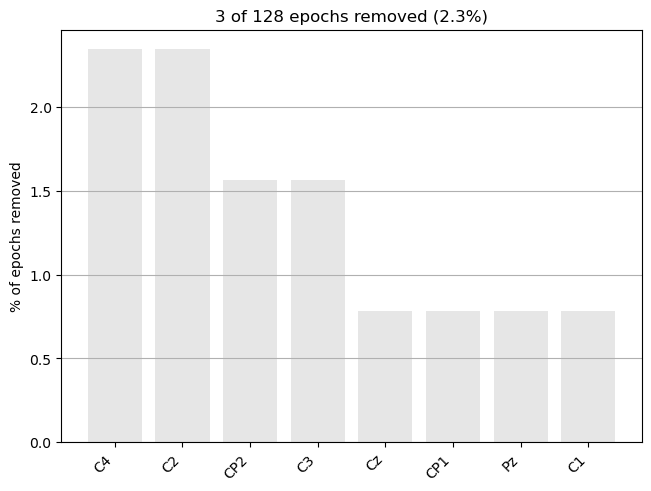

((), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), ('C2', 'C4'), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), ('C3', 'C1', 'Cz', 'C2', 'C4', 'CP1', 'CP2', 'Pz'), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), ('C3', 'C2', 'C4', 'CP2'), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), (), ())
épocas cargadas: 125


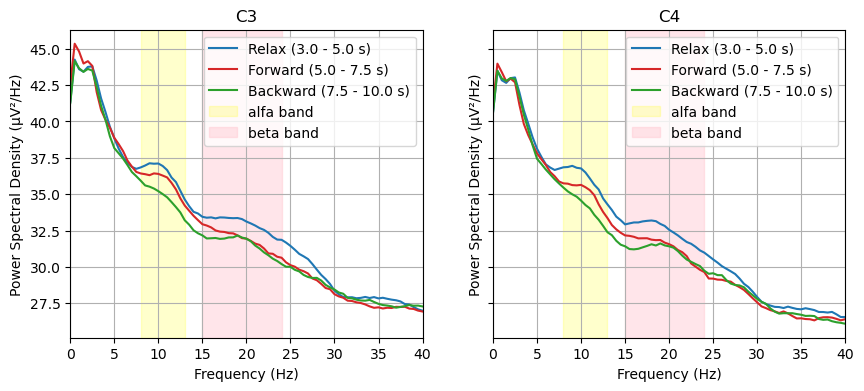

In [ ]:
from BCI2kReader import BCI2kReader as b2k  # Library for reading BCI2000 files
import os                                   # Library to read file directories
import numpy as np                          # Library for array management
import pandas as pd                         # Library for managing data in tables
import matplotlib.pyplot as plt             # Library for plotting data
import math                                 # Library for mathematical operations and constants
import mne                                  # EEG/EMG processing library

import numpy as np
import matplotlib.pyplot as plt
import mne

def plot_c3_trial_dynamics(preOrPost, subject, condition, fs=2400, method='multitaper', window_position = 0):
    """
    Filtra, segmenta y grafica la dinámica espectral del electrodo C3 
    comparando las fases de Relax, Forward y Backward.
    """

    if preOrPost == 'pre':
        file_eeg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_eeg-epo.fif")
        epochs = mne.read_epochs(file_eeg_pre, preload=True, verbose=False)
    elif preOrPost == 'post':
        file_eeg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_eeg-epo.fif")
        epochs = mne.read_epochs(file_eeg_post, preload=True, verbose=False)

    #Rechazo por amplitud
    # data = epochs.get_data()
    # # 2. Define el índice del canal objetivo y tu umbral de amplitud (en volts, tesla, etc.)
    # ch_name = 'C3'  # Nombre exacto de tu canal
    # ch_index = epochs.ch_names.index(ch_name)
    # threshold = 100e-6   # Ejemplo: 100 µV

    # print(data.shape)  # (n_epochs, n_channels, n_times)

    # # 3. Calcula el pico a pico (max - min) por época solo para el canal seleccionado
    # ptp_channel = np.ptp(data[:, ch_index, :], axis=1)

    # # 4. Identifica las épocas que superan el umbral
    # bad_epochs_idx = np.where(ptp_channel > threshold)[0]

    # # 5. Descarta las épocas defectuosas en tu objeto Epochs
    # epochs.drop(bad_epochs_idx, reason=f'Exceso de amplitud en {ch_name}')


    epochs.reject_tmin = 3.0  # Tiempo mínimo para aplicar el rechazo
    epochs.reject_tmax = 10.0 - 1/FS  # Tiempo máximo para aplicar el rechazo
    epochs.drop_bad(reject=dict(eeg=100e-6), verbose=False)  # Ajusta el umbral según tus necesidades

    epochs.plot_drop_log()

    # Verifica qué épocas fueron eliminadas
    print(epochs.drop_log)

    #sub_epochs.plot(scalings=dict(eeg=50e-6))

    #Quitar Luego
    print("épocas cargadas:", len(epochs))
        
    # 1. Filtrado de la señal (1 - 60 Hz)
    epochs_filt = epochs.copy().filter(l_freq=1.0, h_freq=60.0, verbose=False)
    
    # 2. Segmentación del Trial según tus tiempos específicos
    # Usamos tmax=9.9 en backward para evitar errores si el trial corta exactamente en 10.0

    if window_position == 0: # Standard: Relax (3-5s), Forward (5-7.5s), Backward (7.5-10s)
        tmin_forward=5.0
        tmax_forward=7.5

        tmin_backward=7.5
        tmax_backward=10.0
    elif window_position == 1: # Centered: Relax (3-5s), Forward (5.25-7.25s), Backward (7.75-9.75s)
        tmin_forward=5.25
        tmax_forward=7.25

        tmin_backward=7.75
        tmax_backward=9.75
    elif window_position == 2: # Early: Relax (3-5s), Forward (5-7s), Backward (7.5-9.5s)
        tmin_forward=5.0
        tmax_forward=7.0

        tmin_backward=7.5
        tmax_backward=9.5
    else: # Late: Relax (3-5s), Forward (5.5-7.5s), Backward (8-10s)
        tmin_forward=5.5
        tmax_forward=7.5

        tmin_backward=8.0
        tmax_backward=10.0

    epo_relax    = epochs_filt.copy().crop(tmin=3.0, tmax=5.0, verbose=False)  
    epo_forward  = epochs_filt.copy().crop(tmin=tmin_forward, tmax=tmax_forward, verbose=False)  
    epo_backward = epochs_filt.copy().crop(tmin=tmin_backward, tmax=tmax_backward, verbose=False)  
    
    # 3. Estimación de PSD solo para C3
    picks = ['C3'] 

    psd_relax    = epo_relax.compute_psd(method=method, fmin=0, fmax=40, picks=picks, verbose=False)
    psd_forward  = epo_forward.compute_psd(method=method, fmin=0, fmax=40, picks=picks, verbose=False)
    psd_backward = epo_backward.compute_psd(method=method, fmin=0, fmax=40, picks=picks, verbose=False)

    #Quitar luego
    # print(psd_relax.get_data().shape)
    
    # Eje X (Frecuencias)
    freqs_relax = psd_relax.freqs
    freqs_forward = psd_forward.freqs
    freqs_backward = psd_backward.freqs
    
    # 4. Promedio por trials y conversión a Magnitud (dB)
    p_relax    = 10 * np.log10(np.mean(psd_relax.get_data(), axis=(0,1))) + 120
    p_forward  = 10 * np.log10(np.mean(psd_forward.get_data(), axis=(0,1))) + 120
    p_backward = 10 * np.log10(np.mean(psd_backward.get_data(), axis=(0,1))) + 120

    fig, ax = plt.subplots(1,2, figsize=(10, 4), sharey=True)
    
    # Trazado de las tres fases temporales
    ax[0].plot(freqs_relax, p_relax, color='#1f77b4', label='Relax (3.0 - 5.0 s)')       # Verde '#2ca02c'
    ax[0].plot(freqs_forward, p_forward, color='#d62728', label='Forward (5.0 - 7.5 s)')   # Rojo '#d62728'
    ax[0].plot(freqs_backward, p_backward, color='#2ca02c', label='Backward (7.5 - 10.0 s)') # Azul '#1f77b4'
    
    # Sombreado de las Bandas Frecuenciales (Eje X)
    ax[0].axvspan(8, 13, color='yellow', alpha=0.2, label='alfa band')
    ax[0].axvspan(15, 24, color='pink', alpha=0.4, label='beta band')
    
    # Estética y etiquetas
    ax[0].set_title('C3')
    ax[0].set_xlabel('Frequency (Hz)')
    ax[0].set_ylabel('Power Spectral Density (µV²/Hz)')
    ax[0].set_xlim([0, 40])
    
    # Reubicar la leyenda para que no estorbe con las líneas
    ax[0].legend()
    ax[0].grid(True)
    


    # 3. Estimación de PSD solo para C3
    picks = ['C4']

    psd_relax    = epo_relax.compute_psd(method=method, fmin=0, fmax=40, picks=picks, verbose=False)
    psd_forward  = epo_forward.compute_psd(method=method, fmin=0, fmax=40, picks=picks, verbose=False)
    psd_backward = epo_backward.compute_psd(method=method, fmin=0, fmax=40, picks=picks, verbose=False)
    
    # Eje X (Frecuencias)
    freqs_relax = psd_relax.freqs
    freqs_forward = psd_forward.freqs
    freqs_backward = psd_backward.freqs


    # 4. Promedio por trials y conversión a Magnitud (dB)
    p_relax    = 10 * np.log10(np.mean(psd_relax.get_data(), axis=(0, 1))) + 120
    p_forward  = 10 * np.log10(np.mean(psd_forward.get_data(), axis=(0, 1))) + 120
    p_backward = 10 * np.log10(np.mean(psd_backward.get_data(), axis=(0, 1))) + 120
    
    
    # Trazado de las tres fases temporales
    ax[1].plot(freqs_relax, p_relax, color='#1f77b4', label='Relax (3.0 - 5.0 s)')       # Verde '#2ca02c'
    ax[1].plot(freqs_forward, p_forward, color='#d62728', label='Forward (5.0 - 7.5 s)')   # Rojo '#d62728'
    ax[1].plot(freqs_backward, p_backward, color='#2ca02c', label='Backward (7.5 - 10.0 s)') # Azul '#1f77b4'
    
    # Sombreado de las Bandas Frecuenciales (Eje X)
    ax[1].axvspan(8, 13, color='yellow', alpha=0.2, label='alfa band')
    ax[1].axvspan(15, 24, color='pink', alpha=0.4, label='beta band')
    
    # Estética y etiquetas
    ax[1].set_title('C4')
    ax[1].set_xlabel('Frequency (Hz)')
    ax[1].set_ylabel('Power Spectral Density (µV²/Hz)')
    ax[1].set_xlim([0, 40])
    
    # Reubicar la leyenda para que no estorbe con las líneas
    ax[1].legend()
    ax[1].grid(True)




    #plt.tight_layout()
    plt.show()
    
    # Restaurar el estilo por defecto de Matplotlib
    # plt.style.use('default')

# ==============================================================================
# EJEMPLO DE USO (Cópialo en tu celda de ejecución)
# ==============================================================================
subject = "15"
condition = "stim"
preOrPost = "pre" 
# method = 'multitaper'  # 'welch' o 'multitaper'
method = 'multitaper'

#epochs_pre_crudo = mne.read_epochs(file_eeg_pre, preload=True, verbose=False)
print("Sin rechazos por amplitud")
Preprocessed_Data_Folder = r"C:\Yoyi\Preprocessed Data"
# plot_c3_trial_dynamics(preOrPost, subject=subject, condition=condition, method=method, window_position=0)

plot_c3_trial_dynamics(preOrPost, subject=subject, condition=condition, method=method, window_position=2)

# plot_c3_trial_dynamics(preOrPost, subject=subject, condition=condition, method=method, window_position=3)


# 3.3 Testing EEG Band Power extraction

In [2]:
import numpy as np
import mne

def extract_band_power(epochs, ch_name='C3', phase='relax', window_position=2, method='multitaper'):
    """
    Calcula la potencia espectral (en dB, escala µV²/Hz) de las bandas Alfa y Beta 
    para un canal y fase específica, preservando la varianza trial por trial.
    """
    # 1. Configuración dinámica de la ventana temporal
    if window_position == 0: #asimetric
        times = {'relax': (3.0, 5.0), 'forward': (5.0, 7.5), 'backward': (7.5, 10.0)}
    elif window_position == 1: #centered
        times = {'relax': (3.0, 5.0), 'forward': (5.25, 7.25), 'backward': (7.75, 9.75)}
    elif window_position == 2: #early
        times = {'relax': (3.0, 5.0), 'forward': (5.0, 7.0), 'backward': (7.5, 9.5)}
        
    tmin, tmax = times.get(phase, (3.0, 5.0)) # Por defecto usa relax si hay error de tipeo
    
    # 2. Segmentación del Trial
    epochs_crop = epochs.copy().crop(tmin=tmin, tmax=tmax)
    
    # 3. Estimación de PSD
    # Evaluamos hasta 40 Hz para ahorrar recursos de cómputo, ya que no nos interesa Gamma aquí
    psd = epochs_crop.compute_psd(method=method, fmin=0, fmax=40, picks=[ch_name], verbose=False)
    
    freqs = psd.freqs
    data = psd.get_data() # Matriz: (n_epochs, n_channels, n_freqs)
    
    # 4. Definición exacta de tus bandas
    alpha_band = (8, 13)
    beta_band = (15, 24)
    
    # Encontrar los índices exactos donde el arreglo de frecuencias coincide con las bandas
    idx_alpha = np.where((freqs >= alpha_band[0]) & (freqs <= alpha_band[1]))[0]
    idx_beta = np.where((freqs >= beta_band[0]) & (freqs <= beta_band[1]))[0]
    
    # 5. Extracción y conversión a escala de microvoltios (1e12 para equiparar tu +120 dB)
    # data_uv = data * 1e12 
    
    # Promediar la potencia solo a lo largo del canal (axis=1) y los bins de frecuencia (axis=2)
    # Esto mantiene intacto el axis=0 (las épocas individuales)
    power_alpha_raw = np.mean(data[:, :, idx_alpha], axis=(1, 2))
    power_beta_raw = np.mean(data[:, :, idx_beta], axis=(1, 2))
    
    # 6. Transformación logarítmica a dB
    power_alpha_db = 10 * np.log10(power_alpha_raw) + 120
    power_beta_db = 10 * np.log10(power_beta_raw) + 120
    
    return power_alpha_db, power_beta_db

#######################STIM########################

subject = "6"
condition = "stim"
#preOrPost = "pre" 
# method = 'multitaper'  # 'welch' o 'multitaper'
method = 'multitaper'

file_eeg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_eeg-epo.fif")
epochs_pre = mne.read_epochs(file_eeg_pre, preload=True, verbose=False)
file_eeg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_eeg-epo.fif")
epochs_post = mne.read_epochs(file_eeg_post, preload=True, verbose=False)

# Extraer arreglos de datos (PRE)
alpha_pre_forward, beta_pre_forward = extract_band_power(epochs_pre, ch_name='C3', phase='forward')

# Extraer arreglos de datos (POST)
alpha_post_forward, beta_post_forward = extract_band_power(epochs_post, ch_name='C3', phase='forward')

alpha_pre_relaxed, beta_pre_relaxed = extract_band_power(epochs_pre, ch_name='C3', phase='relax')

alpha_post_relaxed, beta_post_relaxed = extract_band_power(epochs_post, ch_name='C3', phase='relax')

plt.hist(alpha_pre_relaxed - alpha_pre_forward, bins=30, edgecolor='black')

# 3. Add labels and show the plot
plt.title('Histogram: (alpha_pre_relaxed - alpha_pre_forward)')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.show()

# Ahora tienes las variables listas para tu test de Mann-Whitney
from scipy import stats

alpha_pre_diff_forward = alpha_pre_relaxed - alpha_pre_forward
alpha_post_diff_forward = alpha_post_relaxed - alpha_post_forward
beta_pre_diff_forward = beta_pre_relaxed - beta_pre_forward
beta_post_diff_forward = beta_post_relaxed - beta_post_forward


stat, p_val_alpha = stats.mannwhitneyu(alpha_pre_diff_forward, alpha_post_diff_forward, alternative='two-sided')
print(f"Banda Alfa (8-13 Hz) - Mediana PRE: {np.median(alpha_pre_diff_forward):.2f} dB | POST: {np.median(alpha_post_diff_forward):.2f} dB | p = {p_val_alpha:.4f}")

stat, p_val_beta = stats.mannwhitneyu(beta_pre_diff_forward, beta_post_diff_forward, alternative='two-sided')
print(f"Banda Beta (15-24 Hz) - Mediana PRE: {np.median(beta_pre_diff_forward):.2f} dB | POST: {np.median(beta_post_diff_forward):.2f} dB | p = {p_val_beta:.4f}")


#######################SHAM########################

subject = "6"
condition = "sham"
#preOrPost = "pre" 
# method = 'multitaper'  # 'welch' o 'multitaper'
method = 'multitaper'

file_eeg_pre = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-pre_eeg-epo.fif")
epochs_pre = mne.read_epochs(file_eeg_pre, preload=True, verbose=False)
file_eeg_post = os.path.join(Preprocessed_Data_Folder, f"sub-{subject}_cond-{condition}_blk-post_eeg-epo.fif")
epochs_post = mne.read_epochs(file_eeg_post, preload=True, verbose=False)

# Extraer arreglos de datos (PRE)
alpha_pre_forward, beta_pre_forward = extract_band_power(epochs_pre, ch_name='C3', phase='forward')

# Extraer arreglos de datos (POST)
alpha_post_forward, beta_post_forward = extract_band_power(epochs_post, ch_name='C3', phase='forward')

alpha_pre_relaxed, beta_pre_relaxed = extract_band_power(epochs_pre, ch_name='C3', phase='relax')

alpha_post_relaxed, beta_post_relaxed = extract_band_power(epochs_post, ch_name='C3', phase='relax')

plt.hist(alpha_pre_relaxed - alpha_pre_forward, bins=30, edgecolor='black')

# 3. Add labels and show the plot
plt.title('Histogram: (alpha_pre_relaxed - alpha_pre_forward)')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.show()

# Ahora tienes las variables listas para tu test de Mann-Whitney
from scipy import stats

alpha_pre_diff_forward = alpha_pre_relaxed - alpha_pre_forward
alpha_post_diff_forward = alpha_post_relaxed - alpha_post_forward
beta_pre_diff_forward = beta_pre_relaxed - beta_pre_forward
beta_post_diff_forward = beta_post_relaxed - beta_post_forward


stat, p_val_alpha = stats.mannwhitneyu(alpha_pre_diff_forward, alpha_post_diff_forward, alternative='two-sided')
print(f"Banda Alfa (8-13 Hz) - Mediana PRE: {np.median(alpha_pre_diff_forward):.2f} dB | POST: {np.median(alpha_post_diff_forward):.2f} dB | p = {p_val_alpha:.4f}")

stat, p_val_beta = stats.mannwhitneyu(beta_pre_diff_forward, beta_post_diff_forward, alternative='two-sided')
print(f"Banda Beta (15-24 Hz) - Mediana PRE: {np.median(beta_pre_diff_forward):.2f} dB | POST: {np.median(beta_post_diff_forward):.2f} dB | p = {p_val_beta:.4f}")



NameError: name 'os' is not defined

# 4) EMG Analysis

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import find_peaks

def analizar_frecuencia_emg(senal, fs):
    """
    Realiza el análisis FFT de una señal EMG.
    
    Args:
        senal (np.array): Datos de la señal EMG.
        fs (int): Frecuencia de muestreo en Hz.
    """
    n = len(senal)
    
    # 1. Eliminar el componente DC (Centrar la señal)
    senal_centrada = senal - np.mean(senal)
    
    # 2. Calcular la FFT
    # Usamos rfft para señales reales, es más eficiente
    yf = fft(senal_centrada)
    xf = fftfreq(n, 1 / fs)

    # Solo nos interesa la mitad positiva del espectro
    frecuencias = xf[:n // 2]
    amplitud = 2.0 / n * np.abs(yf[:n // 2])
    potencia = amplitud**2

    # 3. Detección de picos prominentes
    # prominence: asegura que el pico destaque sobre el ruido circundante
    # distance: evita detectar múltiples puntos de un mismo pico ancho
    indices_picos, propiedades = find_peaks(potencia, prominence=np.max(potencia)*0.25, distance=10)

    frecuencias_picos = frecuencias[indices_picos]
    potencia_picos = potencia[indices_picos]

    # 4. Graficación
    plt.figure(figsize=(12, 6))

    # Gráfico en el tiempo
    plt.subplot(2, 1, 1)
    tiempo = np.linspace(0, n / fs, n)
    plt.plot(tiempo, senal, color='steelblue')
    plt.title('Señal EMG Original (Dominio del Tiempo)')
    plt.xlabel('Tiempo (s)')
    plt.ylabel('Amplitud (mV)')
    plt.grid(True)

    # Gráfico en frecuencia (Espectro de Potencia)
    plt.subplot(2, 1, 2)
    plt.plot(frecuencias, potencia, color='crimson')

    # Resaltar picos detectados
    # plt.scatter(frecuencias_picos, potencia_picos, color='black', marker='x', s=100, label='Picos Detectados')
    
    # Anotar las frecuencias de los picos más altos
    # for i, freq in enumerate(frecuencias_picos):
    #     plt.annotate(f'{freq:.1f} Hz', (freq, potencia_picos[i]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

    plt.title('Espectro de Potencia (Dominio de la Frecuencia)')
    plt.xlabel('Frecuencia (Hz)')
    plt.ylabel('Potencia')
    plt.xlim(0, fs / 2)  # Límite de Nyquist
    plt.grid(True)

    plt.tight_layout()
    #plt.savefig('analisis_emg_fft.png')
    print("Análisis completado. Gráfica guardada como 'analisis_emg_fft.png'.")

    print(f"Picos detectados en las frecuencias: {frecuencias_picos}")
    return frecuencias_picos, potencia_picos

# Ejemplo de uso con señal sintética
if __name__ == "__main__":
    fs = 2400  # Frecuencia de muestreo típica 1kHz
    t = np.linspace(0, 7, fs)
    # Simulación de EMG: Ruido gaussiano modulado con frecuencias dominantes
    # emg_simulada = 0.5 * np.sin(2 * np.pi * 60 * t) + np.random.normal(0, 0.2, fs)

    emg = data3D_EMG[100,6,:]  # Usar la señal EMG real del primer canal del primer trial
    
    analizar_frecuencia_emg(emg, fs)

NameError: name 'data3D_EMG' is not defined

# 5) Other Analysis

IDs únicos detectados:
 [1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19]
Conteo por tipo de sesión:
 (stim o sham)
stim    18
sham    16
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     34 non-null     object 
 1   Tipo de Sesión         34 non-null     object 
 2   Pre Dynamómetro        33 non-null     float64
 3   Pre 9HPT Derecha 1     34 non-null     float64
 4   Pre 9HPT Derecha 2     34 non-null     float64
 5   Pre 9HPT Izquierda 1   34 non-null     float64
 6   Pre 9HPT Izquierda 2   34 non-null     float64
 7   Post Dynamómetro       33 non-null     float64
 8   Post 9HPT Derecha 1    34 non-null     float64
 9   Post 9HPT Derecha 2    34 non-null     float64
 10  Post 9HPT Izquierda 1  34 non-null     float64
 11  Post 9HPT Izquierda 2  34 non-null     float64
dtype

,ID,Tipo de Sesión,Pre Dynamómetro,Pre 9HPT Derecha 1,Pre 9HPT Derecha 2,Pre 9HPT Izquierda 1,Pre 9HPT Izquierda 2,Post Dynamómetro,Post 9HPT Derecha 1,Post 9HPT Derecha 2,Post 9HPT Izquierda 1,Post 9HPT Izquierda 2
4,3,stim,24.3,25.10,22.26,22.24,19.47,24.4,20.64,19.44,21.02,20.05
5,4,stim,32.0,31.21,29.61,31.55,29.48,32.2,32.50,31.05,34.34,29.50
6,5,stim,27.8,25.96,23.42,28.09,25.39,25.9,23.44,23.15,22.27,25.14
7,6,stim,21.2,22.78,24.33,23.68,22.04,16.9,23.33,22.47,24.28,23.33
8,7,stim,33.1,21.01,16.63,22.78,19.25,30.6,21.44,18.62,23.06,22.08
9,8,sham,25.2,18.83,21.12,20.28,22.23,21.8,17.02,17.93,20.12,21.15
10,9,stim,39.3,18.37,19.87,20.63,19.62,38.8,21.77,18.27,24.32,21.21
11,5,sham,33.8,22.10,21.18,22.81,21.78,30.8,23.56,22.46,28.37,23.81
12,7,sham,31.5,17.98,16.54,19.25,18.16,31.4,19.20,16.22,19.87,19.80
13,6,sham,24.6,20.28,17.78,19.83,19.96,24.2,21.00,22.03,21.66,19.45


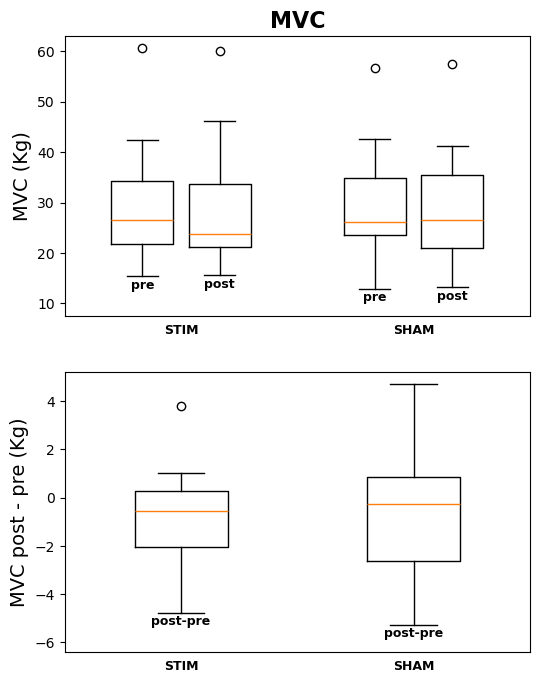

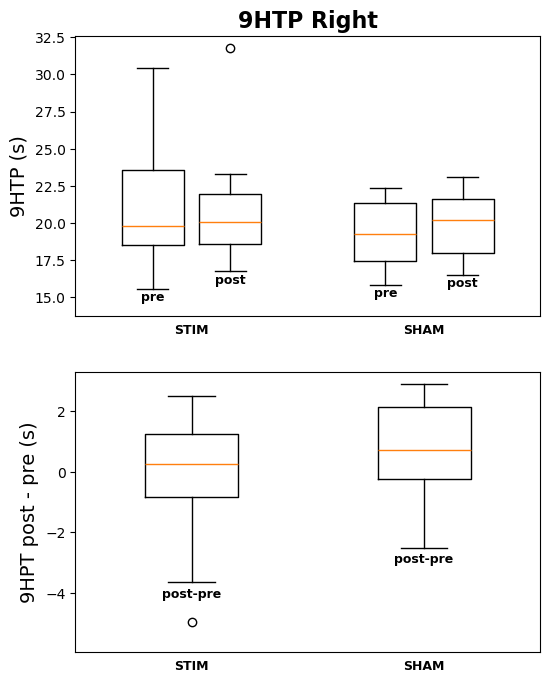

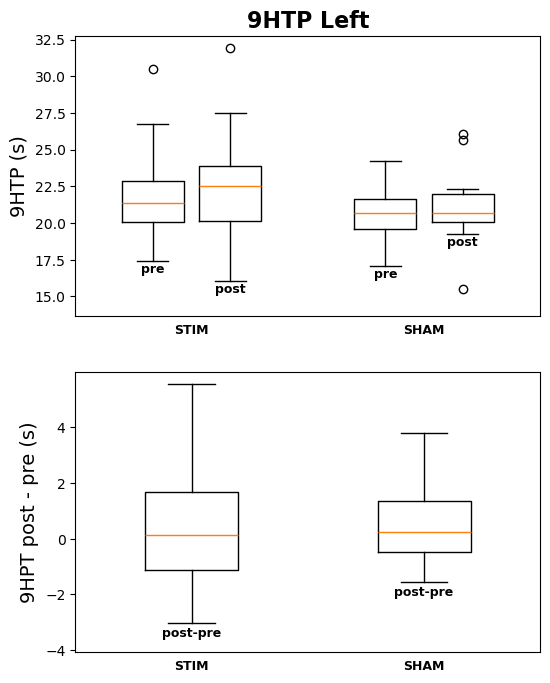

In [7]:
import pandas as pd
import matplotlib.pyplot as plt  
import numpy as np

# 1. Cargar el archivo Excel (hoja principal)
DATA_DIR = r"C:\Yoyi\Raw Data"
excel_path = DATA_DIR + r"\StepByStep.xlsx"
df_raw = pd.read_excel(excel_path, sheet_name=0)
#Testing
print("IDs únicos detectados:\n", df_raw.iloc[2:, 0].unique())
print("Conteo por tipo de sesión:\n", df_raw.iloc[2:, 1].value_counts())

# 2. Definir los índices de las columnas solicitadas
# [ID, Tipo, Pre Dyno, Pre 9HPT (D1, D2, I1, I2), Post Dyno, Post 9HPT (D1, D2, I1, I2)]
cols_idx = [0, 1, 2, 3, 4, 5, 6, 26, 22, 23, 24, 25]

col_names = [
    "ID",
    "Tipo de Sesión",
    "Pre Dynamómetro",
    "Pre 9HPT Derecha 1",
    "Pre 9HPT Derecha 2",
    "Pre 9HPT Izquierda 1",
    "Pre 9HPT Izquierda 2",
    "Post Dynamómetro",
    "Post 9HPT Derecha 1",
    "Post 9HPT Derecha 2",
    "Post 9HPT Izquierda 1",
    "Post 9HPT Izquierda 2",
]

# 3. Extraer desde la fila 2 en adelante (omitiendo los encabezados originales de Excel)
df_clean = df_raw.iloc[2:, cols_idx].copy()
df_clean.columns = col_names

# 4. Eliminar filas vacías (si las hubiera) y resetear el índice
df_clean = df_clean.dropna(subset=["ID"]).reset_index(drop=True)

# 5. Convertir las columnas de métricas a tipo numérico (float)
numeric_cols = df_clean.columns[2:]
df_clean[numeric_cols] = df_clean[numeric_cols].apply(pd.to_numeric, errors="coerce")

# Verificar el resultado
print(df_clean.info())
df_clean = df_clean[4:] #Elimina sujetos 1 y 2
display(df_clean)

#PLOTS
# Create a figure and an axes object
fig, axs = plt.subplots(2,1, figsize=(6, 8))#, sharex=True)

mvc_stim = df_clean[df_clean["Tipo de Sesión"] == "stim"][["Pre Dynamómetro", "Post Dynamómetro"]].values
mvc_sham = df_clean[df_clean["Tipo de Sesión"] == "sham"][["Pre Dynamómetro", "Post Dynamómetro"]].values

MVC_STIM = np.array(mvc_stim).T
MVC_SHAM = np.array(mvc_sham).T

# Plot the box plot
# fig.suptitle('MVC', fontsize=16, fontweight='bold')
axs[0].set_title('MVC', fontsize=16, fontweight='bold')
axs[0].set_ylabel(r'MVC (Kg)', rotation='vertical', fontsize=14)#, labelpad=15)

x_locations = [0.5, 1, 2, 2.5]

bp = axs[0].boxplot([MVC_STIM[0],MVC_STIM[1],MVC_SHAM[0],MVC_SHAM[1]], positions=x_locations, widths=0.4)
axs[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[0].set_ylim(ymin=axs[0].get_ylim()[0]-3, ymax=None)

text_offset = -0.075  # Ajusta este valor según sea necesario para que el texto no se superponga con los ticks

# Extrallendo coordenadas de bigotes
bigote_inf_stim_0 = bp['caps'][0].get_ydata()[0]
bigote_inf_stim_1 = bp['caps'][2].get_ydata()[0]
bigote_inf_sham_0 = bp['caps'][4].get_ydata()[0]
bigote_inf_sham_1 = bp['caps'][6].get_ydata()[0]

axs[0].text(x_locations[0], bigote_inf_stim_0-3, 'pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[0].text(x_locations[1], bigote_inf_stim_1-3, 'post', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[0].text((x_locations[0]+ x_locations[1])/2, text_offset, 'STIM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs[0].get_xaxis_transform(), clip_on=False)

axs[0].text(x_locations[2],  bigote_inf_sham_0-3, 'pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[0].text(x_locations[3],  bigote_inf_sham_1-3, 'post', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[0].text((x_locations[2]+ x_locations[3])/2, text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs[0].get_xaxis_transform(), clip_on=False)

MVC_STIM_DIFF = MVC_STIM[1] - MVC_STIM[0]
MVC_SHAM_DIFF = MVC_SHAM[1] - MVC_SHAM[0]

# Plot the box plot
axs[1].set_ylabel(r'MVC post - pre (Kg)', rotation='vertical', fontsize=14)#, labelpad=15)

x_locations = [1, 2]

bp = axs[1].boxplot([MVC_STIM_DIFF, MVC_SHAM_DIFF], positions = x_locations, widths=0.4)

# Extrallendo coordenadas de bigotes
bigote_inf_stim = bp['caps'][0].get_ydata()[0]
bigote_inf_sham = bp['caps'][2].get_ydata()[0]

axs[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs[1].set_ylim(ymin=axs[1].get_ylim()[0]-0.6, ymax=None)

axs[1].text(x_locations[0], bigote_inf_stim-0.6, 'post-pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[1].text(x_locations[1], bigote_inf_sham-0.6, 'post-pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs[1].text(x_locations[0], text_offset, 'STIM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs[1].get_xaxis_transform(), clip_on=False)
axs[1].text(x_locations[1], text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs[1].get_xaxis_transform(), clip_on=False)

# Display the plot
plt.show()
output_path = os.path.join(output_dir, f"MVC.pdf")
fig.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure


#PLOTS 2
# Create a figure and an axes object
fig2, axs2 = plt.subplots(2,1, figsize=(6, 8))#, sharex=True)

temp_df = df_clean.copy()
temp_df["Pre 9HTP Derecha"] = temp_df[["Pre 9HPT Derecha 1", "Pre 9HPT Derecha 2"]].mean(axis=1)
temp_df["Pre 9HTP Izquierda"] = temp_df[["Pre 9HPT Izquierda 1", "Pre 9HPT Izquierda 2"]].mean(axis=1)
temp_df["Post 9HTP Derecha"] = temp_df[["Post 9HPT Derecha 1", "Post 9HPT Derecha 2"]].mean(axis=1)
temp_df["Post 9HTP Izquierda"] = temp_df[["Post 9HPT Izquierda 1", "Post 9HPT Izquierda 2"]].mean(axis=1)

nine_htp_right_stim = temp_df[temp_df["Tipo de Sesión"] == "stim"][["Pre 9HTP Derecha", "Post 9HTP Derecha"]].values
nine_htp_right_sham = temp_df[temp_df["Tipo de Sesión"] == "sham"][["Pre 9HTP Derecha", "Post 9HTP Derecha"]].values
nine_htp_left_stim = temp_df[temp_df["Tipo de Sesión"] == "stim"][["Pre 9HTP Izquierda", "Post 9HTP Izquierda"]].values
nine_htp_left_sham = temp_df[temp_df["Tipo de Sesión"] == "sham"][["Pre 9HTP Izquierda", "Post 9HTP Izquierda"]].values


NINE_HTP_RIGHT_STIM = np.array(nine_htp_right_stim).T
NINE_HTP_RIGHT_SHAM = np.array(nine_htp_right_sham).T
NINE_HTP_LEFT_STIM = np.array(nine_htp_left_stim).T
NINE_HTP_LEFT_SHAM = np.array(nine_htp_left_sham).T


# Plot the box plot
# fig2.suptitle('MVC', fontsize=16, fontweight='bold')
axs2[0].set_title('9HTP Right', fontsize=16, fontweight='bold')
axs2[0].set_ylabel(r'9HTP (s)', rotation='vertical', fontsize=14)

x_locations = [0.5, 1, 2, 2.5]

bp = axs2[0].boxplot([NINE_HTP_RIGHT_STIM[0],NINE_HTP_RIGHT_STIM[1],NINE_HTP_RIGHT_SHAM[0],NINE_HTP_RIGHT_SHAM[1]], positions=x_locations, widths=0.4)
axs2[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[0].set_ylim(ymin=axs2[0].get_ylim()[0]-1, ymax=None)

text_offset = -0.075  # Ajusta este valor según sea necesario para que el texto no se superponga con los ticks

# Extrallendo coordenadas de bigotes
bigote_inf_stim_0 = bp['caps'][0].get_ydata()[0]
bigote_inf_stim_1 = bp['caps'][2].get_ydata()[0]
bigote_inf_sham_0 = bp['caps'][4].get_ydata()[0]
bigote_inf_sham_1 = bp['caps'][6].get_ydata()[0]

axs2[0].text(x_locations[0], bigote_inf_stim_0-1, 'pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[0].text(x_locations[1], bigote_inf_stim_1-1, 'post', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[0].text((x_locations[0] + x_locations[1]) / 2, text_offset, 'STIM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs2[0].get_xaxis_transform(), clip_on=False)

axs2[0].text(x_locations[2], bigote_inf_sham_0-1, 'pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[0].text(x_locations[3], bigote_inf_sham_1-1, 'post', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[0].text((x_locations[2]+ x_locations[3])/2, text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs2[0].get_xaxis_transform(), clip_on=False)
#axs2[2].text(0.75, ymin-0.25, 'Movement: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')

NINE_HTP_RIGHT_STIM_DIFF = NINE_HTP_RIGHT_STIM[1] - NINE_HTP_RIGHT_STIM[0]
NINE_HTP_RIGHT_SHAM_DIFF = NINE_HTP_RIGHT_SHAM[1] - NINE_HTP_RIGHT_SHAM[0]
NINE_HTP_LEFT_STIM_DIFF = NINE_HTP_LEFT_STIM[1] - NINE_HTP_LEFT_STIM[0]
NINE_HTP_LEFT_SHAM_DIFF = NINE_HTP_LEFT_SHAM[1] - NINE_HTP_LEFT_SHAM[0]

# Plot the box plot
axs2[1].set_ylabel(r'9HPT post - pre (s)', rotation='vertical', fontsize=14)

x_locations = [1, 2]

bp = axs2[1].boxplot([NINE_HTP_RIGHT_STIM_DIFF, NINE_HTP_RIGHT_SHAM_DIFF], positions=x_locations, widths=0.4)

# Extrallendo coordenadas de bigotes
bigote_inf_stim = bp['caps'][0].get_ydata()[0]
bigote_inf_sham = bp['caps'][2].get_ydata()[0]

axs2[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs2[1].set_ylim(ymin=axs2[1].get_ylim()[0]-0.6, ymax=None)

axs2[1].text(x_locations[0], bigote_inf_stim-0.6, 'post-pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[1].text(x_locations[1], bigote_inf_sham-0.6, 'post-pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs2[1].text(x_locations[0], text_offset, 'STIM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs2[1].get_xaxis_transform(), clip_on=False)
axs2[1].text(x_locations[1], text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs2[1].get_xaxis_transform(), clip_on=False)


# Display the plot
plt.show()
output_path = os.path.join(output_dir, f"9HTP_Right.pdf")
fig2.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure

# Plot the box plot
fig3, axs3 = plt.subplots(2,1, figsize=(6, 8))#, sharex=True)

# fig3.suptitle('MVC', fontsize=16, fontweight='bold')
axs3[0].set_title('9HTP Left', fontsize=16, fontweight='bold')
axs3[0].set_ylabel(r'9HTP (s)', rotation='vertical', fontsize=14)

x_locations = [0.5, 1, 2, 2.5]

bp = axs3[0].boxplot([NINE_HTP_LEFT_STIM[0],NINE_HTP_LEFT_STIM[1],NINE_HTP_LEFT_SHAM[0],NINE_HTP_LEFT_SHAM[1]], positions=x_locations, widths=0.4)
axs3[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs3[0].set_ylim(ymin=axs3[0].get_ylim()[0]-1, ymax=None)

text_offset = -0.075  # Ajusta este valor según sea necesario para que el texto no se superponga con los ticks

# Extrallendo coordenadas de bigotes
bigote_inf_stim_0 = bp['caps'][0].get_ydata()[0]
bigote_inf_stim_1 = bp['caps'][2].get_ydata()[0]
bigote_inf_sham_0 = bp['caps'][4].get_ydata()[0]
bigote_inf_sham_1 = bp['caps'][6].get_ydata()[0]

axs3[0].text(x_locations[0], bigote_inf_stim_0-1, 'pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs3[0].text(x_locations[1], bigote_inf_stim_1-1, 'post', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs3[0].text((x_locations[0] + x_locations[1]) / 2, text_offset, 'STIM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs3[0].get_xaxis_transform(), clip_on=False)

axs3[0].text(x_locations[2], bigote_inf_sham_0-1, 'pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs3[0].text(x_locations[3], bigote_inf_sham_1-1, 'post', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs3[0].text((x_locations[2]+ x_locations[3])/2, text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs3[0].get_xaxis_transform(), clip_on=False)
#axs3[2].text(0.75, ymin-0.25, 'Movement: D1', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')

NINE_HTP_LEFT_STIM_DIFF = NINE_HTP_LEFT_STIM[1] - NINE_HTP_LEFT_STIM[0]
NINE_HTP_LEFT_SHAM_DIFF = NINE_HTP_LEFT_SHAM[1] - NINE_HTP_LEFT_SHAM[0]

# Plot the box plot
axs3[1].set_ylabel(r'9HPT post - pre (s)', rotation='vertical', fontsize=14)

x_locations = [1, 2]

bp = axs3[1].boxplot([NINE_HTP_LEFT_STIM_DIFF, NINE_HTP_LEFT_SHAM_DIFF], positions=x_locations, widths=0.4)

# Extrallendo coordenadas de bigotes
bigote_inf_stim = bp['caps'][0].get_ydata()[0]
bigote_inf_sham = bp['caps'][2].get_ydata()[0]

axs3[1].tick_params(axis='x', which='both', bottom=False, labelbottom=False)

axs3[1].set_ylim(ymin=axs3[1].get_ylim()[0]-0.6, ymax=None)

axs3[1].text(x_locations[0], bigote_inf_stim-0.6, 'post-pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs3[1].text(x_locations[1], bigote_inf_sham-0.6, 'post-pre', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold')
axs3[1].text(x_locations[0], text_offset, 'STIM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs3[1].get_xaxis_transform(), clip_on=False)
axs3[1].text(x_locations[1], text_offset, 'SHAM', ha='center', va='bottom', fontsize=9, rotation=0, color='k', zorder=11, fontweight='bold', transform=axs3[1].get_xaxis_transform(), clip_on=False)


# Display the plot
plt.show()
output_path = os.path.join(output_dir, f"9HTP_Left.pdf")
fig3.savefig(output_path, dpi=600, bbox_inches='tight') # Save the figure




# 5.1) MVC and 9HTP Analysis

In [3]:
import pandas as pd
import numpy as np

def process_clinical_excel(excel_filepath, output_csv):
    """
    Lee el archivo de registro clínico StepByStep.xlsx, promedia las 
    repeticiones de 9HPT por cada mano, y convierte la estructura ancha 
    en un formato largo ideal para rmANOVA.
    """
    print("=" * 80)
    print(f"1. CARGANDO REGISTRO CLÍNICO DESDE: {excel_filepath}")
    print("=" * 80)
    
    try:
        # Leemos el Excel saltando las dos primeras filas de encabezados complejos (skiprows=2)
        # Usamos los índices exactos de las columnas que nos interesan basándonos en tu archivo
        columnas_interes = [0, 1, 2, 3, 4, 5, 6, 22, 23, 24, 25, 26]
        nombres_columnas = [
            'Subject', 'Stimulation', 'Pre_MVC', 
            'Pre_9HPT_D1', 'Pre_9HPT_D2', 'Pre_9HPT_I1', 'Pre_9HPT_I2', 
            'Post_9HPT_D1', 'Post_9HPT_D2', 'Post_9HPT_I1', 'Post_9HPT_I2', 
            'Post_MVC'
        ]
        
        df_raw = pd.read_excel(
            excel_filepath, 
            sheet_name='Hoja1', 
            usecols=columnas_interes, 
            skiprows=2, 
            names=nombres_columnas
        )
    except Exception as e:
        print(f"Error al cargar el archivo: {e}")
        return

    # Limpiar filas vacías (donde no hay Subject)
    df_raw = df_raw.dropna(subset=['Subject']).copy()
    
    # Asegurar tipos de datos
    df_raw['Subject'] = df_raw['Subject'].astype(int).astype(str) # Quita decimales si los hay y pasa a texto
    df_raw['Stimulation'] = df_raw['Stimulation'].str.strip().str.upper() # Homologar 'stim' y 'sham' a 'STIM', 'SHAM'
    
    # ==============================================================================
    # 2. Promediado de Repeticiones del 9HPT
    # ==============================================================================
    print("Promediando las repeticiones del 9HPT por mano...")
    
    # Promedios PRE
    df_raw['PRE_9HPT_Derecha'] = df_raw[['Pre_9HPT_D1', 'Pre_9HPT_D2']].mean(axis=1)
    df_raw['PRE_9HPT_Izquierda'] = df_raw[['Pre_9HPT_I1', 'Pre_9HPT_I2']].mean(axis=1)
    
    # Promedios POST
    df_raw['POST_9HPT_Derecha'] = df_raw[['Post_9HPT_D1', 'Post_9HPT_D2']].mean(axis=1)
    df_raw['POST_9HPT_Izquierda'] = df_raw[['Post_9HPT_I1', 'Post_9HPT_I2']].mean(axis=1)
    
    # Renombrar columnas de MVC para homologar el formato CONDICION_METRICA
    df_raw = df_raw.rename(columns={
        'Pre_MVC': 'PRE_MVC',
        'Post_MVC': 'POST_MVC'
    })
    
    # Seleccionamos solo las columnas ya procesadas
    columnas_finales = [
        'Subject', 'Stimulation', 
        'PRE_MVC', 'POST_MVC', 
        'PRE_9HPT_Derecha', 'POST_9HPT_Derecha',
        'PRE_9HPT_Izquierda', 'POST_9HPT_Izquierda'
    ]
    df_procesado = df_raw[columnas_finales].copy()

    # ==============================================================================
    # 3. Transformación a Formato Largo (Melting)
    # ==============================================================================
    print("Transformando estructura de datos a formato largo (Long Format)...")
    
    # Derretimos el dataframe
    df_melted = df_procesado.melt(
        id_vars=['Subject', 'Stimulation'], 
        var_name='Time_Metric', 
        value_name='Valor'
    )
    
    # Separamos el Tiempo (PRE/POST) de la Métrica (MVC, 9HPT_Derecha, etc.)
    # Como usamos el formato TIEMPO_METRICA (ej. PRE_MVC), dividimos por el primer guion bajo
    df_melted[['Time', 'Metric']] = df_melted['Time_Metric'].str.split('_', n=1, expand=True)
    
    # Reestructuramos (Pivot) para que cada métrica tenga su propia columna
    df_pivot = df_melted.pivot_table(
        index=['Subject', 'Stimulation', 'Time'], 
        columns='Metric', 
        values='Valor',
        aggfunc='first'
    ).reset_index()

    # ==============================================================================
    # 4. Filtrado de Diseño Cross-Over (Sujetos Completos)
    # ==============================================================================
    print("\nFiltrando sujetos con sesiones incompletas...")
    conteo_sujetos = df_pivot.groupby('Subject').size()
    sujetos_completos = conteo_sujetos[conteo_sujetos == 4].index.tolist()
    
    df_final = df_pivot[df_pivot['Subject'].isin(sujetos_completos)]
    
    # Ordenar para que aparezcan lógicamente (PRE antes de POST)
    df_final['Time'] = pd.Categorical(df_final['Time'], categories=['PRE', 'POST'], ordered=True)
    df_final = df_final.sort_values(by=['Subject', 'Stimulation', 'Time'])
    
    # Exportación
    df_final.to_csv(output_csv, index=False)
    print(f"\n¡Éxito! Matriz clínica exportada a: {output_csv}")
    print("\nPrevisualización de los datos tabulados:")
    print(df_final.head(8).to_string(index=False))

# ==============================================================================
# EJECUCIÓN
# ==============================================================================
if __name__ == '__main__':
    ARCHIVO_EXCEL = r"C:\Yoyi\Raw Data"+ r"\StepByStep.xlsx"
    ARCHIVO_SALIDA_CSV = "Datos_Clinicos_MVC_9HTP.csv"
    
    process_clinical_excel(ARCHIVO_EXCEL, ARCHIVO_SALIDA_CSV)

1. CARGANDO REGISTRO CLÍNICO DESDE: C:\Yoyi\Raw Data\StepByStep.xlsx
Promediando las repeticiones del 9HPT por mano...
Transformando estructura de datos a formato largo (Long Format)...

Filtrando sujetos con sesiones incompletas...

¡Éxito! Matriz clínica exportada a: Datos_Clinicos_MVC_9HTP.csv

Previsualización de los datos tabulados:
Subject Stimulation Time  9HPT_Derecha  9HPT_Izquierda  MVC
      1        SHAM  PRE        22.500          20.640  NaN
      1        SHAM POST        19.005          18.030  NaN
      1        STIM  PRE        18.465          20.355 44.6
      1        STIM POST        20.755          18.625 41.0
     10        SHAM  PRE        16.455          17.355 12.9
     10        SHAM POST        16.695          20.770 13.2
     10        STIM  PRE        18.685          19.890 15.4
     10        STIM POST        18.075          18.025 16.4


# 5.2) ANOVA y Post-Hoc

CARGANDO DATOS CLÍNICOS DESDE: Datos_Clinicos_MVC_9HTP.csv

[AUDITORÍA DE MUESTRA - CLÍNICA]
Sujetos excluidos (Edad): ['1', '2']
Total de sujetos analizados con Cross-Over completo (N = 13): ['5', '6', '7', '8', '9', '10', '11', '12', '13', '16', '17', '18', '19']

[GENERANDO GRÁFICAS BOXPLOT...]


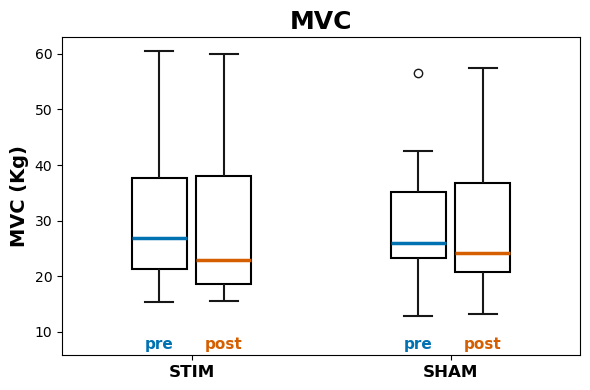

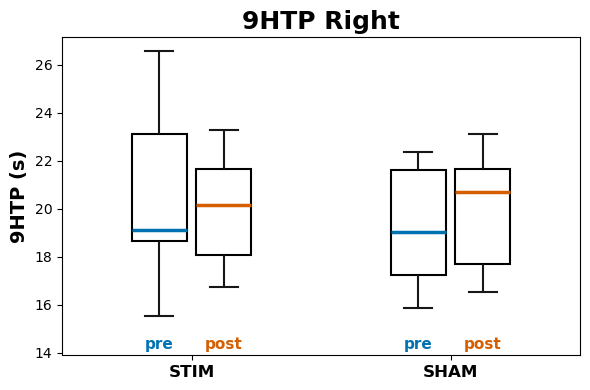

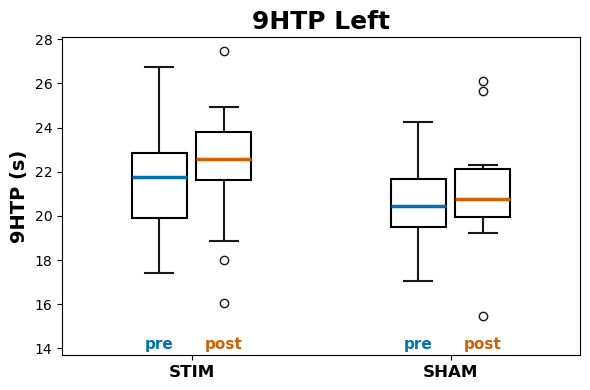


ANÁLISIS PARA LA VARIABLE: MVC

--- 1. SHAPIRO-WILK NORMALITY TEST (MVC) ---
                    W      pval  normal
Stimulation                            
SHAM         0.930328  0.078897    True
STIM         0.874691  0.004456   False
  [!] ADVERTENCIA: Los datos de MVC presentan un sesgo significativo (p < 0.05).
      Considera aplicar una transformación si los resultados del ANOVA son marginales.

--- 2. rmANOVA RESULTS (MVC) ---
Main Effect of Time:        F = 3.125, p = 0.102
Main Effect of Stimulation: F = 0.003, p = 0.960
Time x Stim Interaction:    F = 0.007, p = 0.935

--- 3. POST-HOC ANALYSIS (BONFERRONI) - MVC ---
Comparison: PRE vs POST within STIM
p-corr (Bonferroni): 0.359
Hedges g (Effect Size): -0.067

ANÁLISIS PARA LA VARIABLE: 9HPT_Derecha

--- 1. SHAPIRO-WILK NORMALITY TEST (9HPT_Derecha) ---
                    W      pval  normal
Stimulation                            
SHAM         0.928168  0.070092    True
STIM         0.974848  0.750288    True
  [v] EXCELENT

In [14]:
import pandas as pd
import pingouin as pg
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar avisos de pandas/pingouin para una salida limpia
warnings.filterwarnings('ignore')

def graficar_boxplot(df, metrica, titulo, ylabel):
    """
    Genera un boxplot minimalista agrupado por Stim y Time, 
    garantizando el orden visual correcto de izquierda a derecha.
    """
    plt.figure(figsize=(6, 4))
    
    # Crear el boxplot base
    ax = sns.boxplot(
        data=df, 
        x='Stimulation', 
        y=metrica, 
        hue='Time', 
        order=['STIM', 'SHAM'], 
        hue_order=['PRE', 'POST'],
        color='white',
        width=0.5,            
        gap=0.15,             
        linewidth=1.5,        
        fliersize=6,
        medianprops=dict(linewidth=2.5) 
    )
    
    # Asegurar que las cajas sean blancas con bordes negros sólidos
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    # ---- CORRECCIÓN: ORDENAR ELEMENTOS DE IZQUIERDA A DERECHA ----
    
    # 1. Identificar y ordenar las MEDIANAS por su posición X en la pantalla
    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    
    # Ahora sí, el orden es visual: [STIM-PRE, STIM-POST, SHAM-PRE, SHAM-POST]
    colores_estandar = ['#0072B2', '#D55E00', '#0072B2', '#D55E00'] 
    
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    # Configuración de Títulos y Ejes
    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('') 
    plt.xticks(fontsize=12, fontweight='bold')
    
    # Eliminar la leyenda predeterminada
    if ax.legend_:
        ax.legend_.remove()
        
    y_min = df[metrica].min()
    y_max = df[metrica].max()
    rango = y_max - y_min
    offset_y = rango * 0.08 
    
    # 2. Identificar y ordenar las CAJAS por su posición X en la pantalla
    cajas = ax.patches[:4]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    
    posiciones_x = []
    for patch in cajas_ordenadas:  
        coordenadas = patch.get_path().get_extents().bounds 
        x_centro = coordenadas[0] + (coordenadas[2] / 2)
        posiciones_x.append(x_centro)
    
    etiquetas = ['pre', 'post', 'pre', 'post']
    
    # Dibujar los textos usando las posiciones X ya ordenadas
    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, 
                ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
    
    # Ajustar los límites del eje Y para no cortar el texto inferior
    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    
    plt.tight_layout()
    plt.show()

def run_clinical_stats(csv_filepath, config_metricas):
    """
    Carga el CSV clínico, filtra sujetos completos (diseño cross-over), 
    y ejecuta Pruebas de Normalidad, rmANOVA y Post-Hocs.
    """
    print("=" * 80)
    print(f"CARGANDO DATOS CLÍNICOS DESDE: {csv_filepath}")
    print("=" * 80)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo '{csv_filepath}'.")
        return
        
    # Asegurar que los factores categóricos sean strings
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str) # Ej: 'STIM', 'SHAM'
    df['Time'] = df['Time'].astype(str)               # Ej: 'PRE', 'POST'

    # ==========================================================
    # 0. FILTRO DE EXCLUSIÓN Y REPORTE DE SUJETOS VÁLIDOS
    # ==========================================================
    # 1. Exclusión manual (Criterios de Edad)
    sujetos_excluidos_manual = ['1', '2'] 
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]
    
    # 2. NUEVO: Filtro Estricto de Diseño Cruzado (Cross-Over)
    # Un sujeto solo es válido si tiene exactamente 4 mediciones clínicas
    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 4].index.tolist()
    sujetos_incompletos = conteo_mediciones[conteo_mediciones != 4].index.tolist()
    
    # Retenemos únicamente a los sujetos con el experimento clínico completo
    df = df[df['Subject'].isin(sujetos_completos)]
    
    # Extraer y ordenar la lista final de sujetos analizados
    sujetos_validos = sorted(df['Subject'].unique().tolist(), key=int)
    n_final = len(sujetos_validos)
    
    print(f"\n[AUDITORÍA DE MUESTRA - CLÍNICA]")
    print(f"Sujetos excluidos (Edad): {sujetos_excluidos_manual}")
    if sujetos_incompletos:
        print(f"Sujetos excluidos (Incompletos/Falta de sesión): {sujetos_incompletos}")
    print(f"Total de sujetos analizados con Cross-Over completo (N = {n_final}): {sujetos_validos}")
    print("=" * 80)

    # ==========================================================
    # 1. GENERACIÓN DE GRÁFICAS ANTES DEL ANÁLISIS
    # ==========================================================
    print("\n[GENERANDO GRÁFICAS BOXPLOT...]")
    for col_name, (titulo, ylabel) in config_metricas.items():
        if col_name in df.columns:
            graficar_boxplot(df, col_name, titulo, ylabel)

    # ==========================================================
    # 2. ANÁLISIS ESTADÍSTICO
    # ==========================================================
    
    for metrica in config_metricas.keys():
        if metrica not in df.columns:
            print(f"\n[!] La métrica {metrica} no se encontró en el archivo. Omitiendo...")
            continue
            
        print(f"\n" + "=" * 70)
        print(f"ANÁLISIS PARA LA VARIABLE: {metrica}")
        print("=" * 70)
        
        try:
            # ------------------------------------------------------------------
            # 1. Prueba de Normalidad (Shapiro-Wilk)
            # ------------------------------------------------------------------
            print(f"\n--- 1. SHAPIRO-WILK NORMALITY TEST ({metrica}) ---")
            
            # Evaluamos la normalidad agrupando por la condición de Estimulación
            normality = pg.normality(data=df, dv=metrica, group='Stimulation')
            print(normality)
            
            # Alerta automática si hay violaciones a la normalidad
            is_normal = normality['normal'].all()
            if not is_normal:
                print(f"  [!] ADVERTENCIA: Los datos de {metrica} presentan un sesgo significativo (p < 0.05).")
                print("      Considera aplicar una transformación si los resultados del ANOVA son marginales.")
            else:
                print(f"  [v] EXCELENTE: Los datos de {metrica} siguen una distribución normal paramétrica.")

            # ------------------------------------------------------------------
            # 2. Análisis rmANOVA de 2 Vías (Stimulation x Time)
            # ------------------------------------------------------------------
            anova = pg.rm_anova(
                data=df, 
                dv=metrica, 
                within=['Stimulation', 'Time'], 
                subject='Subject', 
                detailed=True
            )
            
            print(f"\n--- 2. rmANOVA RESULTS ({metrica}) ---")
            ef_time = anova[anova['Source'] == 'Time']
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_int = anova[anova['Source'] == 'Stimulation * Time']
            
            print(f"Main Effect of Time:        F = {ef_time['F'].values[0]:.3f}, p = {ef_time['p-unc'].values[0]:.3f}")
            print(f"Main Effect of Stimulation: F = {ef_stim['F'].values[0]:.3f}, p = {ef_stim['p-unc'].values[0]:.3f}")
            print(f"Time x Stim Interaction:    F = {ef_int['F'].values[0]:.3f}, p = {ef_int['p-unc'].values[0]:.3f}")
            
            # ------------------------------------------------------------------
            # 3. Comparaciones Post-Hoc con corrección de Bonferroni
            # ------------------------------------------------------------------
            ph = pg.pairwise_tests(
                data=df, 
                dv=metrica, 
                within=['Stimulation', 'Time'], 
                subject='Subject', 
                padjust='bonf', 
                parametric=True
            )
            
            # Filtrar para mostrar la interacción dentro de la condición real (STIM)
            print(f"\n--- 3. POST-HOC ANALYSIS (BONFERRONI) - {metrica} ---")
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
            
            if not ph_stim.empty:
                print(f"Comparison: PRE vs POST within STIM")
                print(f"p-corr (Bonferroni): {ph_stim['p-corr'].values[0]:.3f}")
                print(f"Hedges g (Effect Size): {ph_stim['hedges'].values[0]:.3f}")
            else:
                print("No se encontraron contrastes válidos para mostrar.")
                
        except Exception as e:
            print(f"Error procesando {metrica}: {e}")

# ==============================================================================
# EJECUCIÓN PRINCIPAL
# ==============================================================================
if __name__ == '__main__':
    # Ruta de tu archivo CSV con los datos tabulados de MVC y 9HTP
    ARCHIVO_CSV = "Datos_Clinicos_MVC_9HTP.csv"
    
    # Diccionario de configuración: 'Columna_CSV': ('Título de Gráfica', 'Etiqueta Eje Y')
    configuracion_metricas = {
        'MVC': ('MVC', 'MVC (Kg)'),
        '9HPT_Derecha': ('9HTP Right', '9HTP (s)'),
        '9HPT_Izquierda': ('9HTP Left', '9HTP (s)')
    }
    
    run_clinical_stats(ARCHIVO_CSV, configuracion_metricas)

# 6) Resting State EEG Analysis

In [1]:
import mne
import numpy as np
import pandas as pd
import os
import glob

# ==============================================================================
# 1. Función de Extracción de Potencia Beta por Archivo
# ==============================================================================
def extract_beta_power_from_file(filepath):
    """
    Carga un archivo .fif de épocas, aplica Morlet y extrae la potencia Beta promedio
    (promediada a través del tiempo y las frecuencias) para cada época, manteniendo
    la resolución espacial (todos los canales).
    """
    # Cargar las épocas sin mostrar mucha información en consola
    epochs = mne.read_epochs(filepath, preload=True, verbose=False)
    canales_interes = epochs.ch_names
    
    # Configuración de Morlet Wavelets (1 a 55 Hz)
    freqs = np.arange(1, 56, 1)
    n_cycles = freqs / 2.0
    
    # Aplicar Transformada de Morlet (average=False para extraer por época)
    power = epochs.compute_tfr(
        method="morlet",
        freqs=freqs,
        n_cycles=n_cycles,
        picks=canales_interes,
        return_itc=False,
        average=False, 
        verbose=False
    )
    
    # Extracción exclusiva de la Banda Beta (15 - 29 Hz)
    beta_mask = (freqs >= 15) & (freqs <= 29)
    datos_beta = power.data[:, :, beta_mask, :]
    
    # Promediar sobre frecuencias (eje 2) y tiempo (eje 3)
    # Resultado: array de shape (n_epochs, n_channels)
    beta_power_promedio = np.mean(datos_beta, axis=(2, 3))
    
    # Convertir a DataFrame
    df_epoch_data = pd.DataFrame(beta_power_promedio, columns=canales_interes)
    return df_epoch_data

# ==============================================================================
# 2. Pipeline Principal (Bucle Automático)
# ==============================================================================
def process_all_baselines(preprocessed_folder, output_csv):
    """
    Escanea la carpeta de datos preprocesados buscando registros basales, 
    extrae la potencia Beta, promedia las épocas para asegurar independencia,
    y guarda la matriz final en un CSV para el análisis ANOVA.
    """
    print(f"Buscando archivos basales en: {preprocessed_folder}")
    
    # Buscamos archivos que sigan el patrón de nomenclatura de tus basales
    # Ej: sub-6_cond-stim_blk-basal_pre_eeg-epo.fif
    search_pattern = os.path.join(preprocessed_folder, "*_blk-basal_*_eeg-epo.fif")
    archivos_basales = glob.glob(search_pattern)
    
    if not archivos_basales:
        print("No se encontraron archivos basales. Verifica la ruta.")
        return
        
    print(f"Se encontraron {len(archivos_basales)} archivos. Iniciando extracción...\n")
    
    lista_resultados_finales = []
    
    for filepath in archivos_basales:
        filename = os.path.basename(filepath)
        
        # 1. Extraer metadatos directamente del nombre del archivo
        # sub-6_cond-stim_blk-basal_pre_eeg-epo.fif
        partes = filename.split('_')
        subject_id = partes[0].split('-')[1]  # Extrae '6' de 'sub-6'
        condition = partes[1].split('-')[1].upper()  # Extrae 'STIM' de 'cond-stim'
        
        # Extraer el tiempo (PRE o POST). Asumimos que está justo después de 'blk-basal'
        if 'pre' in filename.lower():
            time = 'PRE'
        elif 'post' in filename.lower():
            time = 'POST'
        else:
            time = 'UNKNOWN'
            
        print(f"Procesando: Sujeto {subject_id} | {condition} | {time}")
        
        # 2. Extraer la potencia de todas las épocas de este archivo
        try:
            df_epochs = extract_beta_power_from_file(filepath)
            
            # 3. PROMEDIADO ESTADÍSTICO (Crucial para el ANOVA)
            # Promediamos el valor de todas las épocas del bloque para crear
            # un solo número resumen por electrodo para este sujeto/condición/tiempo.
            df_sujeto_resumen = df_epochs.mean().to_frame().T
            
            # 4. Añadir las variables categóricas (Factores)
            df_sujeto_resumen['Subject'] = subject_id
            df_sujeto_resumen['Stimulation'] = condition
            df_sujeto_resumen['Time'] = time
            
            lista_resultados_finales.append(df_sujeto_resumen)
            
        except Exception as e:
            print(f"  [!] Error procesando {filename}: {e}")
            
    # ==============================================================================
    # 3. Consolidación y Exportación
    # ==============================================================================
    print("\nConsolidando tabla maestra...")
    df_maestro = pd.concat(lista_resultados_finales, ignore_index=True)
    
    # Reordenamos las columnas para que los metadatos queden al principio
    # (Identificamos cuáles son canales vs metadatos)
    cols_metadatos = ['Subject', 'Stimulation', 'Time']
    cols_canales = [c for c in df_maestro.columns if c not in cols_metadatos]
    df_maestro = df_maestro[cols_metadatos + cols_canales]
    
    # Exportar a CSV
    df_maestro.to_csv(output_csv, index=False)
    print(f"\n¡Éxito! Matriz estadística exportada a: {output_csv}")
    print("\nVisualización de las primeras filas de la tabla lista para rmANOVA:")
    print(df_maestro.head())

# ==============================================================================
# 3. Ejecución
# ==============================================================================
if __name__ == '__main__':
    # Define la ruta a tu carpeta con los .fif y el nombre de salida
    Preprocessed_Data_Folder = r"C:\Yoyi\Preprocessed Data"
    Archivo_Salida_CSV = "Beta_Power_RM_ANOVA.csv"
    
    process_all_baselines(Preprocessed_Data_Folder, Archivo_Salida_CSV)

Buscando archivos basales en: C:\Yoyi\Preprocessed Data
Se encontraron 60 archivos. Iniciando extracción...

Procesando: Sujeto 10 | SHAM | POST
Procesando: Sujeto 10 | SHAM | PRE
Procesando: Sujeto 10 | STIM | POST
Procesando: Sujeto 10 | STIM | PRE
Procesando: Sujeto 11 | SHAM | POST
Procesando: Sujeto 11 | SHAM | PRE
Procesando: Sujeto 11 | STIM | POST
Procesando: Sujeto 11 | STIM | PRE
Procesando: Sujeto 12 | SHAM | POST
Procesando: Sujeto 12 | SHAM | PRE
Procesando: Sujeto 12 | STIM | POST
Procesando: Sujeto 12 | STIM | PRE
Procesando: Sujeto 13 | SHAM | POST
Procesando: Sujeto 13 | SHAM | PRE
Procesando: Sujeto 13 | STIM | POST
Procesando: Sujeto 13 | STIM | PRE
Procesando: Sujeto 14 | SHAM | POST
Procesando: Sujeto 14 | SHAM | PRE
Procesando: Sujeto 15 | STIM | POST
Procesando: Sujeto 15 | STIM | PRE
Procesando: Sujeto 16 | SHAM | POST
Procesando: Sujeto 16 | SHAM | PRE
Procesando: Sujeto 16 | STIM | POST
Procesando: Sujeto 16 | STIM | PRE
Procesando: Sujeto 17 | SHAM | POST
Pro

# 6.1) ANOVA y Post-Hoc

1. CARGANDO DATOS DESDE: Beta_Power_RM_ANOVA.csv

[AUDITORÍA DE MUESTRA - EEG]
Sujetos excluidos (Edad/Ruido): ['1', '2', '10']
Sujetos excluidos (Incompletos/Falta de sesión): ['14', '15', '3', '4']
Total de sujetos analizados con Cross-Over completo (N = 12): ['5', '6', '7', '8', '9', '11', '12', '13', '16', '17', '18', '19']
Calculando pruebas de Normalidad, rmANOVA y Post-Hocs...



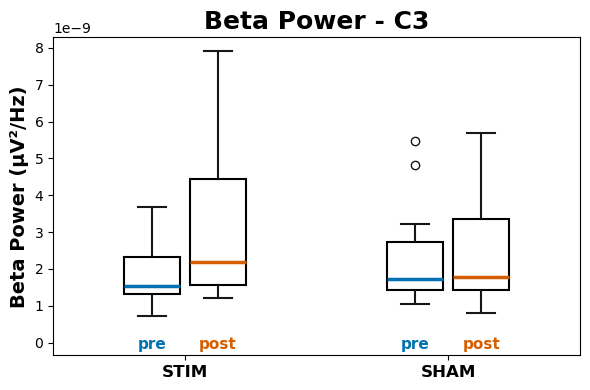

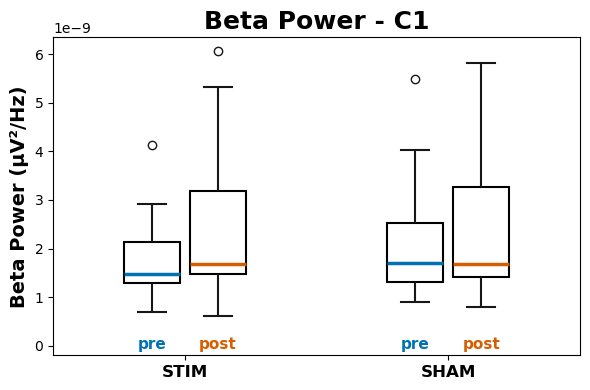

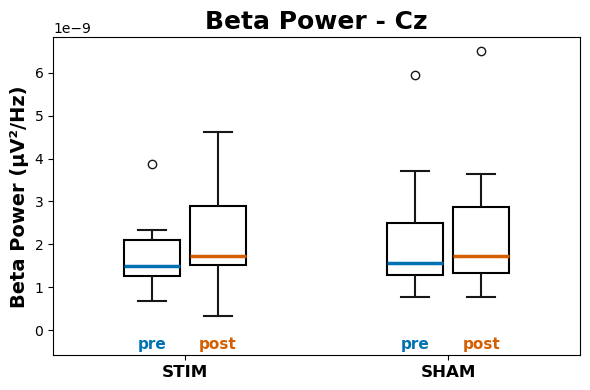

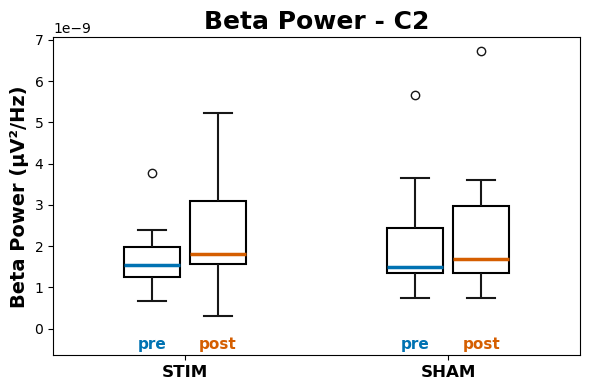

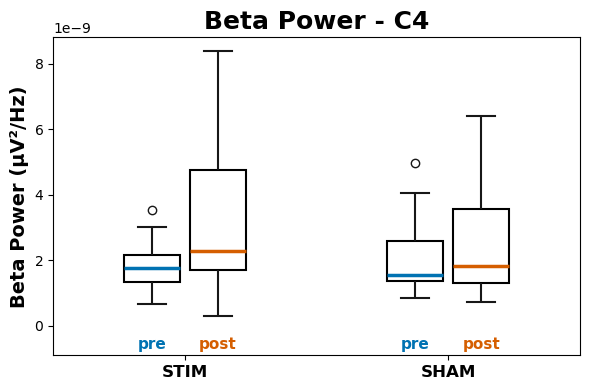

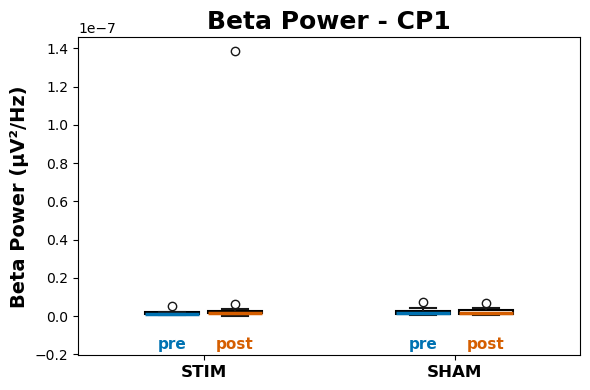

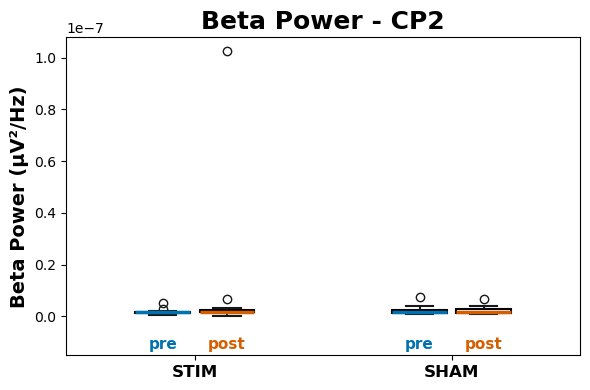

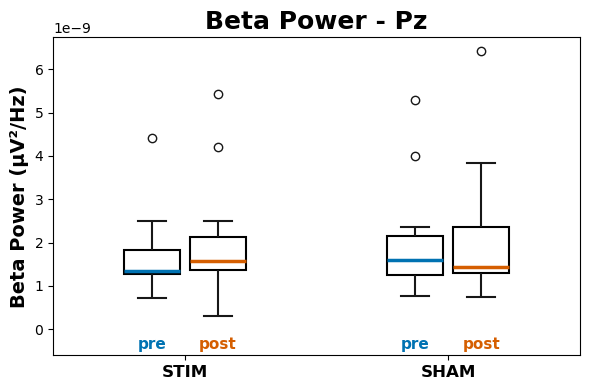

--- TABLE 1. SHAPIRO-WILK NORMALITY TEST (RAW vs LOG-TRANSFORMED) ---
Si 'Log Normal?' es True, la transformación corrigió el sesgo exitosamente.
Electrode  Raw Normal?  Raw Min p-val  Log Normal?  Log Min p-val
       C3        False          0.012         True          0.258
       C1        False          0.016         True          0.480
       Cz        False          0.006         True          0.194
       C2        False          0.007         True          0.269
       C4        False          0.024         True          0.396
      CP1        False          0.000        False          0.004
      CP2        False          0.000        False          0.010
       Pz        False          0.003         True          0.309
------------------------------------------------------------------------------------------

--- TABLE 2. rmANOVA RESULTS (LOG-TRANSFORMED DATA) ---
Electrode Main Effect of Time (F, p) Main Effect of Stimulation (F, p) Time x Stimulation Interaction (F, p)
   

In [17]:
import pandas as pd
import pingouin as pg
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar avisos internos de pandas/pingouin
warnings.filterwarnings('ignore') 

# ==============================================================================
# FUNCIÓN DE GRAFICADO (ESTÉTICA MINIMALISTA Y ORDENADA)
# ==============================================================================
def graficar_boxplot(df, metrica, titulo, ylabel):
    """
    Genera un boxplot minimalista agrupado por Stim y Time, 
    garantizando el orden visual correcto de izquierda a derecha.
    """
    plt.figure(figsize=(6, 4))
    
    # Crear el boxplot base
    ax = sns.boxplot(
        data=df, 
        x='Stimulation', 
        y=metrica, 
        hue='Time', 
        order=['STIM', 'SHAM'], 
        hue_order=['PRE', 'POST'],
        color='white',
        width=0.5,            
        gap=0.15,             
        linewidth=1.5,        
        fliersize=6,
        medianprops=dict(linewidth=2.5) 
    )
    
    # Asegurar que las cajas sean blancas con bordes negros sólidos
    for patch in ax.patches:
        patch.set_edgecolor('black')
        patch.set_facecolor('white')

    # ---- ORDENAR ELEMENTOS DE IZQUIERDA A DERECHA ----
    
    # 1. Identificar y ordenar las MEDIANAS por su posición X en la pantalla
    lineas_medianas = [line for line in ax.lines if line.get_linewidth() == 2.5]
    medianas_ordenadas = sorted(lineas_medianas, key=lambda l: sum(l.get_xdata()) / 2)
    
    # Colores visuales: [STIM-PRE, STIM-POST, SHAM-PRE, SHAM-POST]
    colores_estandar = ['#0072B2', '#D55E00', '#0072B2', '#D55E00'] 
    
    for mediana, color in zip(medianas_ordenadas, colores_estandar):
        mediana.set_color(color)

    # Configuración de Títulos y Ejes
    plt.title(titulo, fontsize=18, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.xlabel('') 
    plt.xticks(fontsize=12, fontweight='bold')
    
    # Eliminar la leyenda predeterminada
    if ax.legend_:
        ax.legend_.remove()
        
    y_min = df[metrica].min()
    y_max = df[metrica].max()
    rango = y_max - y_min
    offset_y = rango * 0.08 
    
    # 2. Identificar y ordenar las CAJAS por su posición X en la pantalla
    cajas = ax.patches[:4]
    cajas_ordenadas = sorted(cajas, key=lambda p: p.get_path().get_extents().bounds[0])
    
    posiciones_x = []
    for patch in cajas_ordenadas:  
        coordenadas = patch.get_path().get_extents().bounds 
        x_centro = coordenadas[0] + (coordenadas[2] / 2)
        posiciones_x.append(x_centro)
    
    etiquetas = ['pre', 'post', 'pre', 'post']
    
    # Dibujar los textos usando las posiciones X ya ordenadas
    for x, etiqueta, color_txt in zip(posiciones_x, etiquetas, colores_estandar):
        ax.text(x, y_min - offset_y, etiqueta, 
                ha='center', va='top', fontweight='bold', fontsize=11, color=color_txt)
    
    # Ajustar los límites del eje Y para no cortar el texto inferior
    plt.ylim(y_min - (rango * 0.15), y_max + (rango * 0.05))
    
    plt.tight_layout()
    # plt.savefig(f"Boxplot_BetaPower_{metrica}.png", dpi=300, bbox_inches='tight') # <-- MUY RECOMENDADO DESCOMENTAR
    plt.show()

# ==============================================================================
# ANÁLISIS ESTADÍSTICO (NORMALIDAD PRE/POST, ANOVA, POST-HOC)
# ==============================================================================
def run_statistical_pipeline(csv_filepath, electrodos):
    """
    Carga el CSV pre-extraído, filtra sujetos completos, ejecuta pruebas 
    de normalidad (crudo vs log), rmANOVA de Dos Vías y Post-Hocs.
    """
    print("=" * 90)
    print(f"1. CARGANDO DATOS DESDE: {csv_filepath}")
    print("=" * 90)
    
    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo '{csv_filepath}'.")
        return
        
    # Asegurar que los factores categóricos sean tratados como strings
    df['Subject'] = df['Subject'].astype(str)
    df['Stimulation'] = df['Stimulation'].astype(str)
    df['Time'] = df['Time'].astype(str)

    # ==========================================================
    # 0. FILTRO DE EXCLUSIÓN Y REPORTE DE SUJETOS VÁLIDOS
    # ==========================================================
    # 1. Exclusión manual (Edad y Ruido Técnico)
    sujetos_excluidos_manual = ['1', '2', '10']
    
    n_inicial = df['Subject'].nunique()
    df = df[~df['Subject'].isin(sujetos_excluidos_manual)]

    # 2. NUEVO: Filtro Estricto de Diseño Cruzado (Cross-Over)
    # Un sujeto solo es válido si tiene exactamente 4 mediciones
    conteo_mediciones = df.groupby('Subject').size()
    sujetos_completos = conteo_mediciones[conteo_mediciones == 4].index.tolist()
    sujetos_incompletos = conteo_mediciones[conteo_mediciones != 4].index.tolist()

    # Retenemos únicamente a los sujetos con el experimento completo
    df = df[df['Subject'].isin(sujetos_completos)]
    
    # Extraer y ordenar la lista final de sujetos analizados
    sujetos_validos = sorted(df['Subject'].unique().tolist(), key=int)
    n_final = len(sujetos_validos)
    
    print(f"\n[AUDITORÍA DE MUESTRA - EEG]")
    print(f"Sujetos excluidos (Edad/Ruido): {sujetos_excluidos_manual}")
    if sujetos_incompletos:
        print(f"Sujetos excluidos (Incompletos/Falta de sesión): {sujetos_incompletos}")
    print(f"Total de sujetos analizados con Cross-Over completo (N = {n_final}): {sujetos_validos}")
    print("=" * 90)
    # ==========================================================
    
    # Crear columna cruzada para agrupar en la prueba de normalidad
    df['Condicion_Cruzada'] = df['Stimulation'] + "_" + df['Time']
    
    tabla_normalidad = []
    tabla_anova = []
    tabla_posthoc = []
    
    print("Calculando pruebas de Normalidad, rmANOVA y Post-Hocs...\n")
    
    for canal in electrodos:
        if canal not in df.columns:
            print(f"  [!] El canal {canal} no existe en el CSV. Omitiendo...")
            continue
            
        try:
            # ------------------------------------------------------------------
            # 0. Generar Gráfica Boxplot (con los datos crudos para mayor interpretabilidad)
            # ------------------------------------------------------------------
            graficar_boxplot(df, canal, f"Beta Power - {canal}", "Beta Power (µV²/Hz)")
            
            # ------------------------------------------------------------------
            # A. Normalidad 1: Datos Crudos
            # ------------------------------------------------------------------
            norm_raw = pg.normality(data=df, dv=canal, group='Condicion_Cruzada')
            pvals_raw = norm_raw['pval'].values
            all_normal_raw = all(p > 0.05 for p in pvals_raw)
            min_pval_raw = min(pvals_raw)
            
            # ------------------------------------------------------------------
            # B. Normalización Logarítmica
            # ------------------------------------------------------------------
            df[f'log_{canal}'] = np.log10(df[canal])
            
            # ------------------------------------------------------------------
            # C. Normalidad 2: Datos Transformados (Log)
            # ------------------------------------------------------------------
            norm_log = pg.normality(data=df, dv=f'log_{canal}', group='Condicion_Cruzada')
            pvals_log = norm_log['pval'].values
            all_normal_log = all(p > 0.05 for p in pvals_log)
            min_pval_log = min(pvals_log)
            
            # Guardar el comparativo de normalidad
            tabla_normalidad.append({
                'Electrode': canal, 
                'Raw Normal?': all_normal_raw, 
                'Raw Min p-val': round(min_pval_raw, 3),
                'Log Normal?': all_normal_log,
                'Log Min p-val': round(min_pval_log, 3)
            })
            
            # ------------------------------------------------------------------
            # D. Análisis rmANOVA de 2 Vías
            # ------------------------------------------------------------------
            anova = pg.rm_anova(
                data=df, 
                dv=f'log_{canal}', 
                within=['Stimulation', 'Time'], 
                subject='Subject', 
                detailed=True
            )
            
            ef_stim = anova[anova['Source'] == 'Stimulation']
            ef_time = anova[anova['Source'] == 'Time']
            ef_int = anova[anova['Source'] == 'Stimulation * Time']
            
            tabla_anova.append({
                'Electrode': canal,
                'Main Effect of Time (F, p)': f"{ef_time['F'].values[0]:.3f}, {ef_time['p-unc'].values[0]:.3f}",
                'Main Effect of Stimulation (F, p)': f"{ef_stim['F'].values[0]:.3f}, {ef_stim['p-unc'].values[0]:.3f}",
                'Time x Stimulation Interaction (F, p)': f"{ef_int['F'].values[0]:.3f}, {ef_int['p-unc'].values[0]:.3f}"
            })
            
            # ------------------------------------------------------------------
            # E. Comparaciones Post-Hoc con corrección de Bonferroni
            # ------------------------------------------------------------------
            ph = pg.pairwise_tests(
                data=df, 
                dv=f'log_{canal}', 
                within=['Stimulation', 'Time'], 
                subject='Subject', 
                padjust='bonf', 
                parametric=True
            )
            
            ph_stim = ph[(ph['Contrast'] == 'Stimulation * Time') & (ph['Stimulation'] == 'STIM')]
            
            if not ph_stim.empty:
                tabla_posthoc.append({
                    'Electrode': canal, 
                    'Comparison': 'PRE vs POST (STIM)',
                    'p-corr (Bonf)': round(ph_stim['p-corr'].values[0], 3),
                    'Hedges g': round(ph_stim['hedges'].values[0], 3)
                })
                
        except Exception as e:
            print(f"  [!] Error procesando el canal {canal}: {e}")

    # ==============================================================================
    # IMPRESIÓN DE REPORTES FORMATEADOS
    # ==============================================================================
    print("=" * 90)
    print("--- TABLE 1. SHAPIRO-WILK NORMALITY TEST (RAW vs LOG-TRANSFORMED) ---")
    print("Si 'Log Normal?' es True, la transformación corrigió el sesgo exitosamente.")
    print(pd.DataFrame(tabla_normalidad).to_string(index=False))
    print("-" * 90)
    
    print("\n" + "=" * 90)
    print("--- TABLE 2. rmANOVA RESULTS (LOG-TRANSFORMED DATA) ---")
    print(pd.DataFrame(tabla_anova).to_string(index=False))
    print("-" * 90)
    
    print("\n" + "=" * 90)
    print("--- TABLE 3. POST-HOC ANALYSIS (BONFERRONI) IN STIM CONDITION ---")
    if tabla_posthoc:
        print(pd.DataFrame(tabla_posthoc).to_string(index=False))
    else:
        print("No se encontraron contrastes Post-Hoc para mostrar.")
    print("=" * 90)


# ==============================================================================
# EJECUCIÓN PRINCIPAL
# ==============================================================================
if __name__ == '__main__':
    ARCHIVO_CSV = "Beta_Power_RM_ANOVA.csv"
    canales_eeg = ['C3', 'C1', 'Cz', 'C2', 'C4', 'CP1', 'CP2', 'Pz']
    
    run_statistical_pipeline(ARCHIVO_CSV, canales_eeg)

# 7) Kinematic Analysis

# 7.1) ANOVA y Post-Hoc